## Assignment_Week7

- For detailed requirements and examples regarding the final project, please refer to the Final Project folder on Blackboard.

**Instructions:**

- Submit your work as a `.ipynb` notebook file or a PDF file on Blackboard.

- PPlease include your name in the filename of your submission.

- <span style="color:blue">**For all narrative sections of this assignment, such as the data description paragraph, please use Markdown cells in the Jupyter notebook. Do not write narratives as commented-out text in Python code cells.**</span> **Alternatively, you may choose to write the narrative portions in a separate Word document and submit both the Word doc and Python code files together.** Please refer to the final project folder on Blackboard for specific examples.

- If applicable, ensure that you label headings, subheadings, and other sections appropriately using Markdown's header formatting for clarity and organization.

- Please make sure all code is executed and displays the corresponding output. If the corresponding output is not displayed, no points will be given.

- **I recommend pasting the content you completed last week into this notebook before continuing with this week's tasks. This way, we can see the previously completed EDA and data preprocessing sections along with the new work.**


**Goal**: Last week, we conducted exploratory data analysis and data preprocessing. This week, we'll continue with model selection and training, and then move on to the initial model evaluation. In the final week, we will complete model optimization and fine-tuning, as well as the final evaluation.

<br>

## Part A. Work completed last week (Week 6): research purpose, dataset description, EDA and preprocessing

*Pasted unchanged, with its saved outputs, as the instructions recommend. Week 6 used a time-based split (train 1993-1996, test 1997); Part B keeps the time-based split but re-fits the preprocessing and redefines the target as a fixed-horizon label (adoption within 365 days of the landmark), following the feedback that end-of-data labels are not comparable across cohorts; a random stratified split is used as a secondary comparison.*

### ANA540 Machine Learning Project

#### Task 0 (from last week): State Your Research Purpose and Questions

<span style="color:GREEN">**Please use 1-2 paragraphs to clearly state your research purpose or define the key questions you aim to address through your analysis.**</span>

Your research purpose explains the core goal or objective of your project. Why are you conducting this study and analysis?


Here are the key considerations for your machine learning project:

#### Define the Problem Statement:

- What specific issue or question do you want to address with machine learning?
- Is there a particular domain or industry you're interested in, such as healthcare, education, or social media?

#### Determine the Type of Machine Learning Problem:

- **Classification**: Will you predict categories or labels? (e.g. spam vs not spam)
- **Regression**: Will you forecast continuous numerical values? (e.g. housing prices)
- **Clustering**: Will you group data based on similarities, without prior labels? (to be covered Week 8)
- **Dimensionality Reduction**: Will you reduce the number of features while retaining information? (e.g. PCA) (to be covered Week 7)

#### Research Purpose

The purpose of this project is to build a **Next-Best-Product (NBP) model for retail banking** that anticipates which existing checking-account customers will go on to adopt a **loan, a credit card, both, or neither**. Banks typically score customers from static snapshots (monthly or quarterly aggregates) and treat adoption as a yes/no outcome. Here, the customer's raw, timestamped transaction stream from their first 90 days with the bank is used to predict their eventual product portfolio. The longer-term goal is to compare conventional tabular classifiers and survival models against a neural **Marked Temporal Point Process (RMTPP)** that works directly in continuous time, and to retain the *time to first adoption* as a second target so that the models can say *when* to make an offer, not just *to whom*. The study uses the Berka (PKDD'99) retail-banking dataset.

This matters for marketing and sales because offers are costly and customers who ignore them are a nuisance, so the bank wants to concentrate effort on customers who are about to need a product. The problem is hard for three reasons. First, adoption is **uneven**: about 31% of accounts adopt anything, and only about 4% adopt both products, so the four classes are strongly imbalanced. Second, observation ends in December 1998, so "neither" really means "not yet" (**right-censoring**). Third, the data are a real time series, so evaluation must respect time: models are trained on accounts opened in 1993–1996 and tested on the unseen 1997 cohort, which mirrors how a bank would deploy a model on new customers.

**Key questions**

1. Which behaviors in a customer's first 90 days (activity level, cash-flow, balance patterns, payment types, demographics, district context) distinguish customers who end up with *neither*, *loan only*, *card only*, or *both*?
2. How accurately can the four-class portfolio outcome be predicted compared with a majority-class baseline, and which model family (tabular ML, survival-based, neural MTPP) performs best on macro-F1, one-vs-rest AUC-ROC and per-class recall?
3. Does a continuous-time sequence model add value beyond hand-engineered aggregates, and how well can it rank customers by *time to first adoption* (concordance index)?
4. Is the model useful for targeting, for example lift in the top decile of predicted loan or card propensity, and does it hold up when applied to a later cohort of customers?

#### Type of Machine Learning Problem

| Aspect | Choice |
|---|---|
| **Primary task** | **Multiclass classification** of final product status: `neither`, `loan_only`, `card_only`, `both` |
| **Secondary task** | **Time-to-event (survival) prediction** of the first adoption, with right-censoring (used by the Cox, Random Survival Forest and RMTPP models in later weeks) |
| **Unit of analysis** | One bank account (4,500 accounts), observed from a fixed **90-day landmark** after opening |
| **Models planned** | Multinomial logistic regression, Random Forest, XGBoost/LightGBM (tabular); Cox-PH and Random Survival Forest (survival); RMTPP in PyTorch (neural MTPP) |

### Task 1: Dataset Description (If you didn’t complete it last week, or if you decide to switch to a new dataset, please complete this task.）

- Remember, the quality and quantity of data can significantly influence the project's outcomes.
  
- Ensure you understand the features present in the dataset and what they represent.


- *Public Datasets: There are numerous publicly available datasets from platforms such as the UCI Machine Learning Repository, Kaggle, Google Dataset Search, US Open Data Portal, and Harvard Dataverse.*

- *Personal or Company Data: If you have access to proprietary data (either collected personally or from a company) that can be publicly disclosed, you may choose to use this. Ensure that the data doesn't violate any privacy guidelines or contain sensitive information.*

#### Write a Description:
<span style="color:GREEN">**For the dataset you choose, please write a concise 1-2 paragraph to describe the dataset,**</span> such as why you chose this dataset and how it relates to your research topic. **Also write down the attributes for each feature (or features you will use) in the dataset**. 

The description should cover:

- **Source**: Where the dataset originates from, including any relevant links or references.
- **Relevance**: Explain the significance of this dataset in relation to your research topic and why it was chosen.
- **Feature Attributes**: Provide a brief overview of the features within the dataset, highlighting the ones you intend to use. For each feature, mention its data type (e.g., numerical, categorical), its meaning, and any unique characteristics.


In addition to the three essential points mentioned above, you may choose to include the following aspects in your dataset description：

- **Contextual Information**: Offer any additional details that might help understand the dataset's context, such as the time period it covers, geographic limitations, or the population it represents.
- **Critical Evaluation**: Reflect on any potential biases, limitations, or challenges within the dataset that could impact your analysis or the generalizability of your findings.

#### Dataset Description

**Source.** The Berka dataset was released for the PKDD'99 Discovery Challenge by Petr Berka and is a real, anonymized extract from a Czech bank. It is widely mirrored (for example on Kaggle and the CTU Relational Dataset Repository); this project uses the eight CSV files in `berka.zip`. It describes about 5,300 clients, 4,500 accounts, 682 loans, 892 credit cards and over one million transactions between January 1993 and December 1998.

**Relevance.** The dataset has what a continuous-time next-best-product study needs and most public banking datasets lack: exact transaction dates and amounts for every account, together with dated loan and card records. That allows adoption to be defined as an event in time, observed against a customer's behavior history, and censored when the observation window ends. It also supports the project's "adopt one, both, or neither" framing directly (loan and card records are independent tables). The Santander Product Recommendation dataset is larger but only monthly, so it cannot support a continuous-time formulation.

**Context and critical evaluation.** The data cover accounts opened 1993–1997 across 77 Czech districts, with transactions observed until 31 December 1998. Limitations to keep in mind: (i) only 4,500 accounts, which is small for a neural model; (ii) a single bank, country and decade; (iii) a loan or card is the outcome of the *bank's approval* as well as the customer's interest, and there is no marketing-contact data, so we model *adoption*, not *response to an offer*; (iv) observation stops in 1998, so later cohorts have shorter follow-up and "neither" includes customers who might adopt later; and (v) several post-adoption traces sit in the transaction table (loan repayments, card withdrawals), which would leak the answer if the full history were used (shown in Task 3).

**Tables and attributes used.** Czech codes are decoded below. Columns I plan to use as predictors are marked ✔; "outcome" columns define the target; "excluded" columns are dropped for the reason stated.

| Table | Column | Type | Meaning / unique characteristics | Use |
|---|---|---|---|---|
| `account` | `account_id`, `district_id` | id | Account key; branch district | key |
| | `frequency` | categorical | Statement issuance: monthly (`POPLATEK MESICNE`), weekly (`POPLATEK TYDNE`), after each transaction (`POPLATEK PO OBRATU`) | ✔ |
| | `date` | date (YYMMDD) | Account opening date (1993–1997); defines the time origin | time origin |
| `client` | `birth_number` | encoded string | `YYMMDD`; month +50 for women, so it yields age at opening and gender | ✔ (age, gender) |
| `disp` | `type` | categorical | `OWNER` or `DISPONENT` (authorized user); links clients, accounts and cards | ✔ (has disponent) |
| `district` | `A2`–`A16` | numeric/categorical | Region, population, urban ratio, average salary, unemployment 1995/96, entrepreneurs per 1,000, crimes 1995/96. District 69 has `?` for two fields | ✔ |
| `trans` | `date` | date | Transaction date (event time) | ✔ |
| | `type` | categorical | `PRIJEM` credit, `VYDAJ` debit, `VYBER` withdrawal (legacy label) | ✔ (mark) |
| | `operation` | categorical | `VKLAD` cash deposit, `VYBER` cash withdrawal, `PREVOD NA UCET` transfer out, `PREVOD Z UCTU` transfer in, `VYBER KARTOU` card withdrawal; blank for interest credits | ✔ (mark) |
| | `k_symbol` | categorical | Purpose: `DUCHOD` pension, `POJISTNE` insurance, `SLUZBY` fees, `SIPO` household payment, `UROK` interest, `SANKC. UROK` penalty interest, `UVER` loan repayment | ✔ (but `UVER` is leakage) |
| | `amount`, `balance` | numeric (CZK) | Transaction size and balance after it; heavy right tail; some negative balances | ✔ |
| | `bank`, `account` | categorical | Counterparty identifiers (about 72–74% missing, filled only for transfers) | excluded (sparse, identifiers) |
| `loan` | `date` | date | Loan granting date | outcome |
| | `amount`, `duration`, `payments`, `status` | numeric / categorical | Loan terms and repayment status (A, B, C, D) | excluded (consequences of the loan) |
| `card` | `issued`, `type` | date / categorical | Card issue date; `junior`, `classic`, `gold` | outcome (`type` excluded) |
| `order` | all | mixed | Standing orders; **no dates**, and includes loan-payment orders | excluded (undated, leaks loan) |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
DATA_DIR = Path("berka")        # folder containing the 8 CSV files from berka.zip
OUT_DIR = Path("processed")     # processed datasets are written here for Weeks 7-8
OUT_DIR.mkdir(exist_ok=True)

LANDMARK_DAYS = 90                         # prediction time = account opening + 90 days
OBS_END = pd.Timestamp("1998-12-31")       # last day of data (right-censoring date)
SPLIT_DATE = pd.Timestamp("1997-01-01")    # time-based split: open before = train, from = test
CLASS_NAMES = ["neither", "loan_only", "card_only", "both"]

In [2]:
def read_table(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", sep=";", low_memory=False)

account, card, client, disp = (read_table(n) for n in ["account", "card", "client", "disp"])
district, loan, order, trans = (read_table(n) for n in ["district", "loan", "order", "trans"])

# Dates are stored as YYMMDD numbers (card dates carry a trailing "00:00:00")
to_date = lambda s: pd.to_datetime(s.astype(str).str[:6], format="%y%m%d")
account["date"] = to_date(account["date"])
loan["date"] = to_date(loan["date"])
card["issued"] = to_date(card["issued"])
trans["date"] = to_date(trans["date"])

tables = {"account": account, "card": card, "client": client, "disp": disp,
          "district": district, "loan": loan, "order": order, "trans": trans}

### Task 3: Exploratory Data Analysis (EDA)
Perform exploratory data analysis on the dataset you have selected. The primary goals of EDA are to gain a deeper understanding of the dataset's characteristics and to identify any issues related to data quality, such as missing values or outliers, that may require attention. EDA is an iterative process that can reveal insights to inform the next steps of your analysis or model building.

Specifically, based on your own dataset, you can explore your dataset from these aspects (*you may choose to address all of the following points or focus on a selection of them that are most relevant to your study's needs*):

- **Sample Size and Basic Information**: Present the overall sample size and review basic dataset information.
- **Descriptive Statistics**: Examine basic statistics for each feature, including count, mean, standard deviation, etc., to get a sense of the data's distribution.
- **Missing Values and Outliers**: Check for missing values and identify any outliers that may need to be addressed.
- **Visualization**: Create various visualizations (e.g., histograms, scatter plots, box plots) to uncover relationships between features and the target variable. Visual analysis can help in identifying patterns, trends, or anomalies.
- **Feature Correlation**: Analyze the correlation between features to understand how they relate to each other and to the target variable. This can highlight potential multicollinearity or identify promising predictors for your model.

<span style="color:GREEN">**After completing your EDA, write 1-2 paragraph documenting the key findings. This should include any significant patterns or relationships uncovered, data quality issues identified, and how these insights could potentially shape your subsequent analysis steps or model selection.**</span>

#### 3.1 Sample size and basic information

,rows,columns
account,4500,4
card,892,4
client,5369,3
disp,5369,4
district,77,16
loan,682,7
order,6471,6
trans,1056320,10


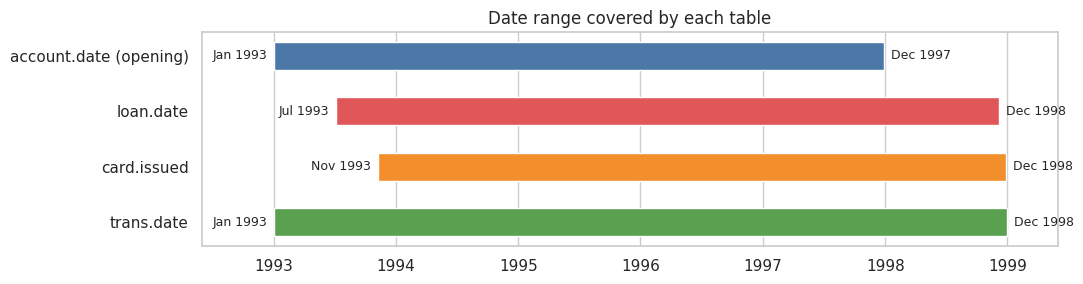

Derived stats:


,count
accounts,4500
accounts with transactions,4500
clients,5369
owners,4500
disponents (authorized users),869
max loans per account,1
max cards per account,1


In [3]:
import matplotlib.dates as mdates

overview = pd.DataFrame({"rows": {k: len(v) for k, v in tables.items()},
                         "columns": {k: v.shape[1] for k, v in tables.items()}})
display(overview)

date_cols = {"account.date (opening)": account["date"], "loan.date": loan["date"],
             "card.issued": card["issued"], "trans.date": trans["date"]}
ranges = pd.DataFrame({k: {"start": v.min(), "end": v.max()} for k, v in date_cols.items()}).T

fig, ax = plt.subplots(figsize=(11, 3))
colors = ["#4C78A8", "#E15759", "#F28E2B", "#59A14F"]
for i, ((name, r), col) in enumerate(zip(ranges.iterrows(), colors)):
    start, end = mdates.date2num(r["start"]), mdates.date2num(r["end"])
    ax.barh(i, end - start, left=start, height=0.5, color=col)
    ax.text(start - 20, i, f"{r['start']:%b %Y}", ha="right", va="center", fontsize=9)
    ax.text(end + 20, i, f"{r['end']:%b %Y}", ha="left", va="center", fontsize=9)
ax.set_yticks(range(len(ranges))); ax.set_yticklabels(ranges.index); ax.invert_yaxis()
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(mdates.date2num(pd.Timestamp("1992-06-01")), mdates.date2num(pd.Timestamp("1999-06-01")))
ax.set(title="Date range covered by each table"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Derived stats:")
summary = pd.Series({
    "accounts": account["account_id"].nunique(),
    "accounts with transactions": trans["account_id"].nunique(),
    "clients": client["client_id"].nunique(),
    "owners": (disp["type"] == "OWNER").sum(),
    "disponents (authorized users)": (disp["type"] == "DISPONENT").sum(),
    "max loans per account": loan.groupby("account_id").size().max(),
    "max cards per account": card.merge(disp, on="disp_id").groupby("account_id").size().max(),
})
summary.to_frame("count")

**Observations.** All 4,500 accounts have a transaction history and exactly one owner. 869 additional clients are authorized users (disponents). No account has more than one loan or one card, so adoption can be treated as a yes/no event per product.

#### 3.2 Descriptive statistics

,count,mean,std,min,25%,50%,75%,max
amount,"1,056,320.00","5,924.15","9,522.74",0.00,135.90,"2,100.00","6,800.00","87,400.00"
balance,"1,056,320.00","38,518.33","22,117.87","-41,125.70","22,402.50","33,143.40","49,603.62","209,637.00"


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
PRIJEM,"405,083.00","7,967.43","11,835.61",0.00,143.50,"1,600.00","12,087.50","74,812.00"
VYBER,"16,666.00","12,516.73","6,593.29","2,001.00","6,738.50","12,103.00","18,081.00","24,997.00"
VYDAJ,"634,571.00","4,446.65","7,375.55",0.00,43.00,"2,042.00","5,200.00","87,400.00"


,transactions
operation,
VYBER,434918
PREVOD NA UCET,208283
(blank = interest credit),183114
VKLAD,156743
PREVOD Z UCTU,65226
VYBER KARTOU,8036


Loans:


,count,mean,std,min,25%,50%,75%,max
amount,682.00,"151,410.18","113,372.41","4,980.00","66,732.00","116,928.00","210,654.00","590,820.00"
duration,682.00,36.49,17.08,12.00,24.00,36.00,48.00,60.00
payments,682.00,"4,190.66","2,215.83",304.00,"2,477.00","3,934.00","5,813.50","9,910.00"


count
loan status         C                     403
                    A                     203
                    D                      45
                    B                      31
card type           classic               659
                    junior                145
                    gold                   88
statement frequency POPLATEK MESICNE     4167
                    POPLATEK TYDNE        240
                    POPLATEK PO OBRATU     93

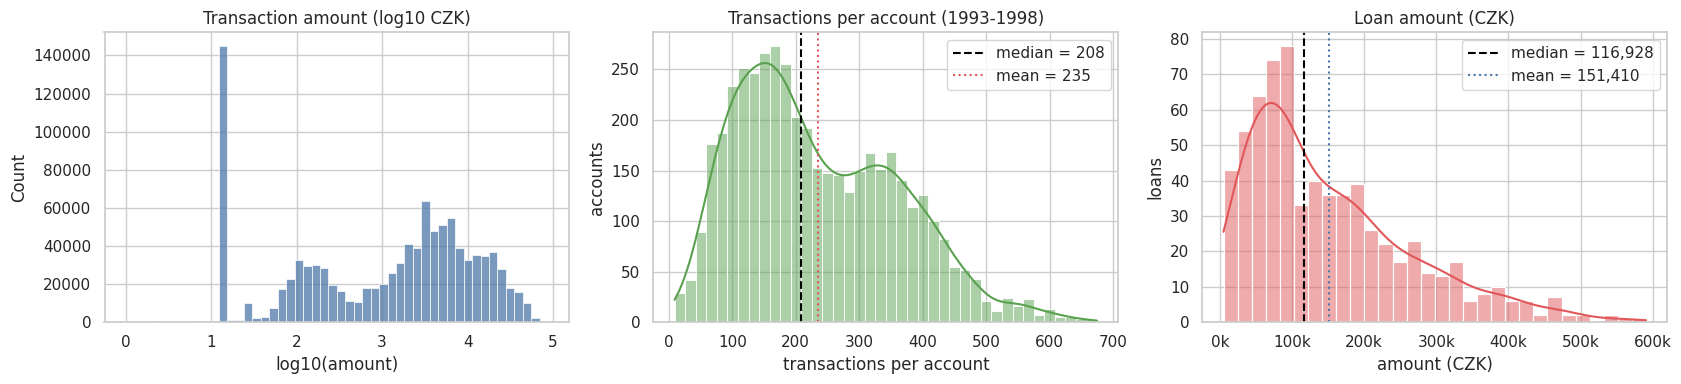

In [4]:
display(trans[["amount", "balance"]].describe().T)
display(trans.groupby("type")["amount"].describe())
display(trans["operation"].fillna("(blank = interest credit)").value_counts().to_frame("transactions"))

per_acct = trans.groupby("account_id").size()
print("Loans:"); display(loan[["amount", "duration", "payments"]].describe().T)
display(pd.concat({"loan status": loan["status"].value_counts(), "card type": card["type"].value_counts(),
                   "statement frequency": account["frequency"].value_counts()}).to_frame("count"))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(np.log10(trans["amount"].clip(lower=1)), bins=50, ax=ax[0], color="#4C78A8")
ax[0].set(title="Transaction amount (log10 CZK)", xlabel="log10(amount)")
sns.histplot(per_acct, bins=40, kde=True, ax=ax[1], color="#59A14F")
ax[1].axvline(per_acct.median(), color="black", ls="--", label=f"median = {per_acct.median():.0f}")
ax[1].axvline(per_acct.mean(), color="#E15759", ls=":", label=f"mean = {per_acct.mean():.0f}")
ax[1].set(title="Transactions per account (1993-1998)", xlabel="transactions per account", ylabel="accounts")
ax[1].legend()
sns.histplot(loan["amount"], bins=30, kde=True, ax=ax[2], color="#E15759")
ax[2].axvline(loan["amount"].median(), color="black", ls="--", label=f"median = {loan['amount'].median():,.0f}")
ax[2].axvline(loan["amount"].mean(), color="#4C78A8", ls=":", label=f"mean = {loan['amount'].mean():,.0f}")
ax[2].set(title="Loan amount (CZK)", xlabel="amount (CZK)", ylabel="loans")
ax[2].xaxis.set_major_formatter(lambda x, _: f"{x/1000:,.0f}k")
ax[2].legend()
plt.tight_layout(); plt.show()

**Observations.** The typical account has 208 transactions over its life (mean 235). Cash withdrawals (`VYBER`, 434,918) are the most frequent operation, followed by transfers out (208,283) and interest credits, which have a blank operation (183,114). Of 682 loans, 403 are running without problems (C), 203 are finished (A) and 76 are unpaid or in debt (B: 31, D: 45). Loan outcomes are consequences of the loan and are not used as predictors. Cards are mostly classic (659), with 145 junior and 88 gold. 92.6% of accounts (4,167) receive monthly statements. Weekly (240) and per-transaction (93) statements are small groups.

#### 3.3 Missing values and outliers

In [5]:
# Standardize missing values: turn "?" and blank / space-only text into real nulls (NaN), then count them
for name, df in tables.items():
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip().replace({"": np.nan, "?": np.nan})

null_counts = {name: df.isna().sum() for name, df in tables.items()}
null_report = pd.concat(null_counts, names=["table", "column"]).rename("nulls").reset_index()
null_report = null_report[null_report["nulls"] > 0]
null_report["% null"] = 100 * null_report["nulls"] / null_report["table"].map({n: len(d) for n, d in tables.items()})
display(null_report.set_index(["table", "column"]).round(2))
print("Total null cells across all tables:", f"{sum(int(s.sum()) for s in null_counts.values()):,}")

nulls  % null
table    column                   
district A12             1    1.30
         A15             1    1.30
order    k_symbol     1379   21.31
trans    operation  183114   17.34
         k_symbol   481881   45.62
         bank       782812   74.11
         account    760931   72.04

Total null cells across all tables: 2,210,119


**Observations.** Placeholder text (`?` in the district table, blank spaces in `k_symbol`) was converted to true nulls so that every kind of missing value is counted the same way. In total there are **2,263,552 null cells**, almost all of them in the transaction table (`operation` 17.3%, `k_symbol` 50.7%, `bank` 74.1%, `account` 72.0%) and in `order.k_symbol` (21.3%). These are structural rather than errors: `operation` is blank exactly for interest credits, `k_symbol` is empty when a transaction has no stated purpose, and `bank`/`account` are filled only for transfers. They are handled by an explicit `none` category (or by dropping the two counterparty columns). The only genuine data gaps are two district fields (unemployment 1995 and crimes 1995) for district 69, Jesenik: 1 of 77 districts, affecting 48 accounts. All other tables are complete.

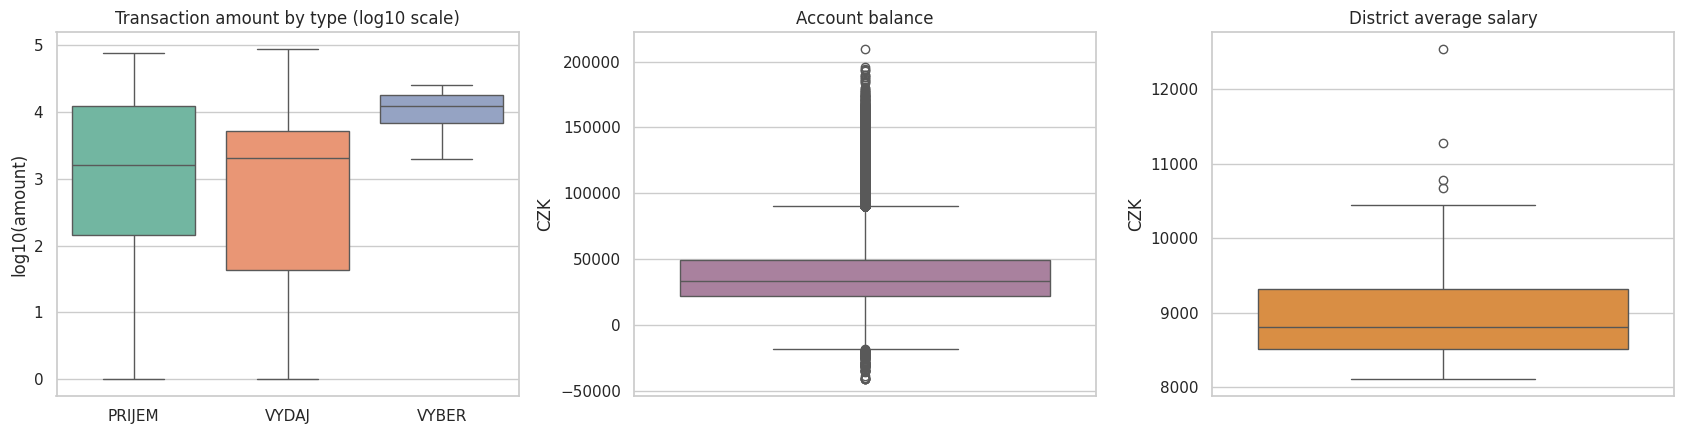

,min,median,max
type,,,
PRIJEM,0.00,"1,600.00","74,812.00"
VYBER,"2,001.00","12,103.00","24,997.00"
VYDAJ,0.00,"2,042.00","87,400.00"


,value
balance median,"33,143.40"
balance upper whisker limit,"90,405.31"
balance min,"-41,125.70"
balance max,"209,637.00"
negative-balance transactions,"2,999.00"
accounts with a negative balance,288.00
zero-amount transactions,14.00


,district,avg salary
0,Hl.m. Praha,12541
7,Mlada Boleslav,11277
25,Plzen - mesto,10787
73,Ostrava - mesto,10673


In [6]:
# Outliers detected using boxplots
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=trans.assign(log_amount=np.log10(trans["amount"].clip(lower=1))), x="type", y="log_amount", ax=ax[0], palette="Set2")
ax[0].set(title="Transaction amount by type (log10 scale)", xlabel="", ylabel="log10(amount)")
sns.boxplot(y=trans["balance"], ax=ax[1], color="#B07AA1"); ax[1].set(title="Account balance", ylabel="CZK")
sns.boxplot(y=district["A11"], ax=ax[2], color="#F28E2B"); ax[2].set(title="District average salary", ylabel="CZK")
plt.tight_layout(); plt.show()

amount_summary = trans.groupby("type")["amount"].agg(["min", "median", "max"])
display(amount_summary)

q1, q3 = trans["balance"].quantile([0.25, 0.75])
display(pd.Series({
    "balance median": trans["balance"].median(),
    "balance upper whisker limit": q3 + 1.5 * (q3 - q1),
    "balance min": trans["balance"].min(),
    "balance max": trans["balance"].max(),
    "negative-balance transactions": (trans["balance"] < 0).sum(),
    "accounts with a negative balance": trans.loc[trans["balance"] < 0, "account_id"].nunique(),
    "zero-amount transactions": (trans["amount"] == 0).sum(),
}).to_frame("value"))

display(district.loc[district["A11"].nlargest(4).index, ["A2", "A11"]].rename(columns={"A2": "district", "A11": "avg salary"}))

**Observations** Transaction amounts are heavily right-skewed: typical values are small (median 1,600 CZK for credits PRIJEM and 2,042 CZK for debits VYDAJ) but the maxima are far larger (74,812 and 87,400 CZK), which is why the left boxplot uses a log10 scale. On that scale the whiskers cover the whole range and no outlier dots appear, so the skew is a long right tail in raw CZK. Legacy VYBER withdrawals are bounded between 2,001 and 24,997 CZK. Account balances center near 33,143 CZK. A dense band of high balances lies above the upper whisker (90,405 CZK), up to a maximum of 209,637 CZK, and a small set of negative balances falls below the lower whisker, down to -41,126 CZK. In total, 2,999 transactions on 288 accounts have a negative balance (overdrafts), and 14 transactions have a zero amount. District average salary is concentrated between about 8,500 and 9,300 CZK, with four districts above the whisker. The highest is Hl.m. Praha (Prague) with 12,541 CZK, as listed in the table above. All of these values are genuine banking behavior, so no rows are removed. The heavy tails are compressed with a signed log in Task 4.

#### 3.4 Defining the target: product status and time to adoption

A customer's status is built from the dated `loan` and `card` records (a card counts whether held by the owner or a disponent):

| Class | Code | Meaning |
|---|---|---|
| `neither` | 0 | No loan and no card by 31 Dec 1998 |
| `loan_only` | 1 | Loan only |
| `card_only` | 2 | Card only |
| `both` | 3 | Both products |

For the survival and MTPP models in later weeks I also keep the **first adoption** (`loan` / `card` / none), the time to it, and a censoring flag.

accounts
first adoption                 none            3096
                               card             758
                               loan             646
order of adoption among 'both' loan first       134
                               card first        36

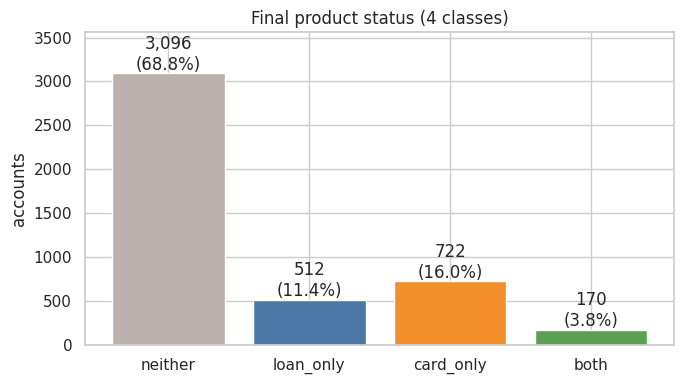

In [7]:
acct = account.rename(columns={"date": "open_date"}).set_index("account_id")

loan_first = loan.groupby("account_id")["date"].min().rename("loan_date")
card_first = (card.merge(disp[["disp_id", "account_id"]], on="disp_id")
                  .groupby("account_id")["issued"].min().rename("card_date"))
acct = acct.join([loan_first, card_first])

acct["has_loan"] = acct["loan_date"].notna()
acct["has_card"] = acct["card_date"].notna()
acct["y"] = acct["has_loan"].astype(int) + 2 * acct["has_card"].astype(int)       # 0 neither, 1 loan, 2 card, 3 both
acct["status4"] = pd.Categorical(acct["y"].map(dict(enumerate(CLASS_NAMES))), categories=CLASS_NAMES)

# first adoption + time to it (days since opening); non-adopters are censored at OBS_END
acct["first_event_date"] = acct[["loan_date", "card_date"]].min(axis=1)
acct["first_event"] = np.select(
    [acct["has_loan"] & (~acct["has_card"] | (acct["loan_date"] <= acct["card_date"])), acct["has_card"]],
    ["loan", "card"], default="none")
acct["event_observed"] = (acct["first_event"] != "none").astype(int)
acct["t_open_days"] = (acct["first_event_date"].fillna(OBS_END) - acct["open_date"]).dt.days
acct["t_from_landmark"] = acct["t_open_days"] - LANDMARK_DAYS
acct["open_year"] = acct["open_date"].dt.year

counts = acct["status4"].value_counts().reindex(CLASS_NAMES)
display(pd.concat({"first adoption": acct["first_event"].value_counts(),
                   "order of adoption among 'both'": acct.loc[acct["y"] == 3].eval("loan_date < card_date").map({True: "loan first", False: "card first"}).value_counts()}).to_frame("accounts"))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 40, f"{v:,}\n({100*v/len(acct):.1f}%)", ha="center")
ax.set(title="Final product status (4 classes)", ylabel="accounts", ylim=(0, counts.max() * 1.15)); plt.tight_layout(); plt.show()

**Observations.** The four classes are strongly imbalanced: `neither` 3,096 (68.8%), `card_only` 722 (16.0%), `loan_only` 512 (11.4%) and `both` 170 (3.8%). In terms of the first product adopted, 646 customers take a loan first and 758 a card first (1,404 accounts, 31.2%). Among the 170 customers with both products, 134 got the loan first and 36 the card first.

#### 3.5 When do customers adopt? Cumulative incidence and time to adoption

Because observation stops in 1998, a Kaplan-Meier style estimate (1 − survival) is used so that non-adopters are treated as *censored* rather than "never". Loan and card curves are estimated separately, since a customer can adopt both.

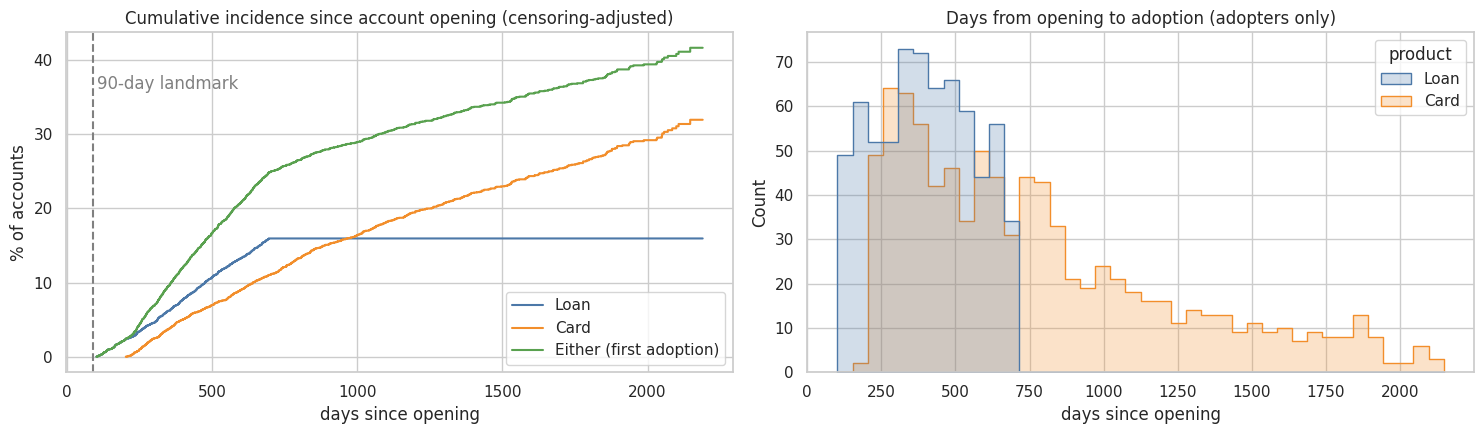

,Loan,Card,Either (first adoption)
cumulative incidence (%),,,
180 days,1.80,0.00,1.80
365 days,6.70,4.20,10.30
730 days,15.90,11.60,25.30
1095 days,15.90,18.10,30.20
1825 days,15.90,26.90,37.40


,min,median,max
days from opening to adoption,,,
Loan,102.00,395.50,697.00
Card,203.00,658.50,"2,147.00"


In [8]:
def cumulative_incidence(duration, observed):
    d = pd.DataFrame({"t": np.asarray(duration), "e": np.asarray(observed).astype(int)})
    g = d.groupby("t")["e"].agg(events="sum", n="size").sort_index()
    g["at_risk"] = g["n"][::-1].cumsum()[::-1]
    g["cif"] = 1 - (1 - g["events"] / g["at_risk"]).cumprod()
    return g["cif"]

curves = {
    "Loan": cumulative_incidence((acct["loan_date"].fillna(OBS_END) - acct["open_date"]).dt.days, acct["has_loan"]),
    "Card": cumulative_incidence((acct["card_date"].fillna(OBS_END) - acct["open_date"]).dt.days, acct["has_card"]),
    "Either (first adoption)": cumulative_incidence(acct["t_open_days"], acct["event_observed"]),
}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for (name, c), col in zip(curves.items(), ["#4C78A8", "#F28E2B", "#59A14F"]):
    ax[0].step(c.index, 100 * c.values, where="post", label=name, color=col)
ax[0].axvline(LANDMARK_DAYS, color="grey", ls="--"); ax[0].text(LANDMARK_DAYS + 15, 36, "90-day landmark", color="grey")
ax[0].set(title="Cumulative incidence since account opening (censoring-adjusted)", xlabel="days since opening", ylabel="% of accounts"); ax[0].legend()

adopt = pd.concat([((acct["loan_date"] - acct["open_date"]).dt.days.dropna().rename("days")).to_frame().assign(product="Loan"),
                   ((acct["card_date"] - acct["open_date"]).dt.days.dropna().rename("days")).to_frame().assign(product="Card")])
sns.histplot(data=adopt, x="days", hue="product", bins=40, element="step", palette=["#4C78A8", "#F28E2B"], ax=ax[1])
ax[1].set(title="Days from opening to adoption (adopters only)", xlabel="days since opening"); plt.tight_layout(); plt.show()

horizon = [180, 365, 730, 1095, 1825]
tbl = pd.DataFrame({n: [100 * c[c.index <= h].iloc[-1] if (c.index <= h).any() else 0 for h in horizon] for n, c in curves.items()}, index=[f"{h} days" for h in horizon])
display(tbl.round(1).rename_axis("cumulative incidence (%)"))
days_to_adopt = pd.DataFrame({"Loan": (acct["loan_date"] - acct["open_date"]).dt.days, "Card": (acct["card_date"] - acct["open_date"]).dt.days})
days_to_adopt.agg(["min", "median", "max"]).T.rename_axis("days from opening to adoption")

**Observations.** Loans are granted between day 102 and day 697 after opening (median 395.5), whereas cards appear between day 203 and day 2,147 (median 658.5). The loan window closes at about two years, so loan incidence plateaus near 16%, while cards keep accumulating (about 27% after five years).

Since, the earliest adoption of any product happens 102 days after opening, so a **90-day landmark** keeps every account in the study (no one has already adopted at prediction time) while giving a short, leakage-free behavior window.

,1993,1994,1995,1996,1997,1998
granted per calendar year,,,,,,
Loans,20,101,90,117,196,158
Cards,1,21,63,116,242,449


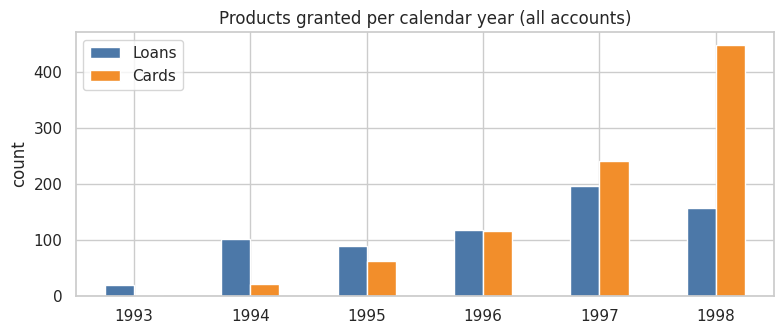

In [9]:
cal = pd.concat([loan["date"].dt.year.value_counts().rename("Loans"), card["issued"].dt.year.value_counts().rename("Cards")], axis=1).sort_index().fillna(0).astype(int)
display(cal.T.rename_axis("granted per calendar year"))
cal.plot(kind="bar", figsize=(8, 3.5), color=["#4C78A8", "#F28E2B"], rot=0)
plt.title("Products granted per calendar year (all accounts)"); plt.ylabel("count"); plt.tight_layout(); plt.show()

Card issuance grows steeply over calendar time (a handful in 1994 to several hundred in 1998), so card adoption reflects the bank's roll-out as well as how long an account has existed; this matters for a time-based split and is revisited in the conclusions.

#### 3.6 Leakage check: post-adoption traces in the transaction table

In [10]:
mk = trans.merge(acct[["loan_date", "card_date"]], left_on="account_id", right_index=True, how="left")
checks = [("k_symbol = UVER (loan repayment)", mk["k_symbol"] == "UVER", "loan_date"),
          ("operation = VYBER KARTOU (card withdrawal)", mk["operation"] == "VYBER KARTOU", "card_date")]
rows = []
for label, mask, col in checks:
    sub = mk[mask]
    rows.append({"marker": label, "transactions": len(sub),
                 "on accounts without product": int(sub[col].isna().sum()),
                 "before adoption date": int((sub["date"] < sub[col]).sum()),
                 "on/after adoption date": int((sub["date"] >= sub[col]).sum()),
                 "earliest (days after adoption)": int((sub["date"] - sub[col]).dt.days.min())})
display(pd.DataFrame(rows).set_index("marker"))

uver_orders = order[order["k_symbol"] == "UVER"]
pd.Series({"accounts with a loan-payment standing order": uver_orders["account_id"].nunique(),
           "accounts with a loan record": loan["account_id"].nunique(),
           "loan-payment orders on accounts with no loan": int((~uver_orders["account_id"].isin(loan["account_id"])).sum())}).to_frame("count")

,transactions,on accounts without product,before adoption date,on/after adoption date,earliest (days after adoption)
marker,,,,,
k_symbol = UVER (loan repayment),13580,0,0,13580,0
operation = VYBER KARTOU (card withdrawal),8036,0,0,8036,1


,count
accounts with a loan-payment standing order,717
accounts with a loan record,682
loan-payment orders on accounts with no loan,35


Loan repayments and card withdrawals **never** appear before the product exists, so using a customer's complete history would let a model "predict" adoption from its consequences. All predictors are therefore built only from transactions up to the 90-day landmark, and loan `status`, `amount`, `duration`, card `type` and the `order` table are excluded. The `order` table lists loan-payment standing orders for 717 accounts although only 682 accounts have a loan (35 such orders sit on accounts with no loan record); because it has no dates it cannot be cut at the landmark.

#### 3.7 Adoption by opening cohort (informs the time-based split)

,neither,loan_only,card_only,both,total,follow-up min (months),median,max
open_year,,,,,,,,
1993,809,114,180,36,1139,57.10,62.90,69.00
1994,293,52,81,13,439,45.20,51.10,57.00
1995,434,83,116,28,661,33.10,38.70,45.00
1996,929,170,200,64,1363,21.10,26.80,33.00
1997,631,93,145,29,898,9.10,15.10,21.00


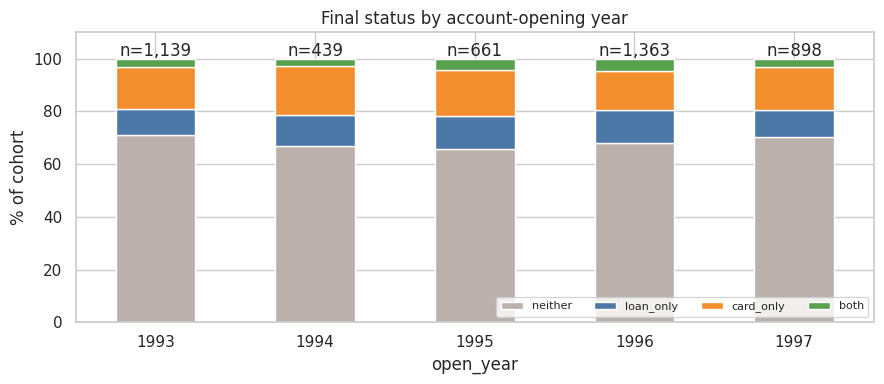

In [11]:
cohort = pd.crosstab(acct["open_year"], acct["status4"])[CLASS_NAMES]
cohort_pct = cohort.div(cohort.sum(axis=1), axis=0) * 100
follow = (((OBS_END - acct["open_date"]).dt.days - LANDMARK_DAYS) / 30.44).groupby(acct["open_year"]).agg(["min", "median", "max"]).round(1)
follow.columns = ["follow-up min (months)", "median", "max"]
display(cohort.assign(total=cohort.sum(axis=1)).join(follow))

ax = cohort_pct.plot(kind="bar", stacked=True, figsize=(9, 4), color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"], rot=0)
for i, tot in enumerate(cohort.sum(axis=1)): ax.text(i, 101, f"n={tot:,}", ha="center")
ax.set(title="Final status by account-opening year", ylabel="% of cohort", ylim=(0, 110)); ax.legend(loc="lower right", ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

#### 3.8 Adoption by customer attributes

,count,mean,std,min,25%,50%,75%,max
age_at_open,"4,500.00",41.22,17.14,10.26,26.51,40.49,53.96,79.44


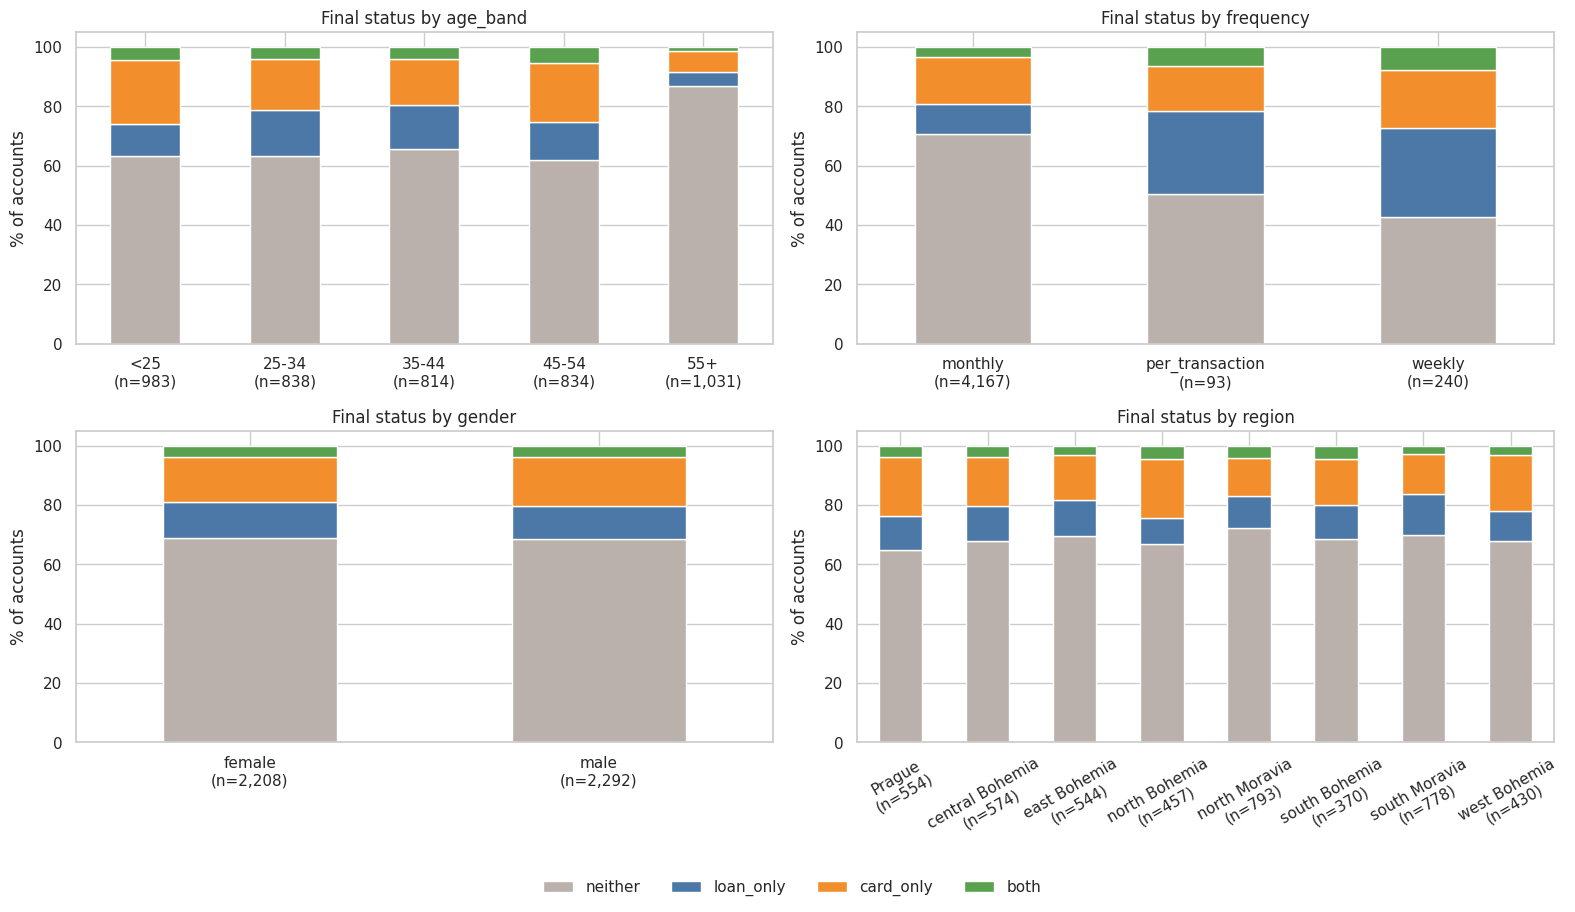

status4                    neither  loan_only  card_only  both     n
variable  group                                                     
age_band  <25                63.20      10.70      21.70  4.50   983
          25-34              63.40      15.30      17.20  4.20   838
          35-44              65.60      14.70      15.60  4.10   814
          45-54              61.90      12.90      19.80  5.40   834
          55+                86.70       4.90       7.10  1.30  1031
frequency monthly            70.70       9.90      15.90  3.50  4167
          per_transaction    50.50      28.00      15.10  6.50    93
          weekly             42.50      30.00      19.60  7.90   240
gender    female             68.90      11.90      15.30  3.80  2208
          male               68.70      10.90      16.80  3.70  2292
region    Prague             64.80      11.40      20.00  3.80   554
          central Bohemia    67.90      11.70      16.40  4.00   574
          east Bohemia       69.50      12.30      15.10  3.10   544
          north Bohemia      67.00       8.80      19.70  4.60   457
          north Moravia      72.40      10.50      12.90  4.30   793
          south Bohemia      68.40      11.60      15.40  4.60   370
          south Moravia      69.90      13.60      13.50  3.00   778
          west Bohemia       67.90      10.00      18.80  3.30   430

In [12]:
# Owner age and gender come from the encoded birth number (YYMMDD, month + 50 for women)
owner = disp[disp["type"] == "OWNER"].merge(client, on="client_id").set_index("account_id")
b = owner["birth_number"].astype(int)
month = (b // 100) % 100
owner["is_female"] = (month > 50).astype(int)
owner["birth_date"] = pd.to_datetime({"year": 1900 + b // 10000, "month": np.where(month > 50, month - 50, month), "day": b % 100})
acct = acct.join(owner[["is_female", "birth_date"]])
acct["age_at_open"] = (acct["open_date"] - acct["birth_date"]).dt.days / 365.25
acct["has_disponent"] = (disp.groupby("account_id").size() > 1).astype(int).reindex(acct.index)
acct["frequency"] = acct["frequency"].map({"POPLATEK MESICNE": "monthly", "POPLATEK TYDNE": "weekly", "POPLATEK PO OBRATU": "per_transaction"})
acct["gender"] = acct["is_female"].map({0: "male", 1: "female"})
acct["age_band"] = pd.cut(acct["age_at_open"], [0, 25, 35, 45, 55, 100], right=False, labels=["<25", "25-34", "35-44", "45-54", "55+"])
acct = acct.join(district.set_index("A1")[["A3"]].rename(columns={"A3": "region"}), on="district_id")
display(acct["age_at_open"].describe().to_frame().T)

colors = ["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"]
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, col in zip(axes.ravel(), ["age_band", "frequency", "gender", "region"]):
    ct = pd.crosstab(acct[col], acct["status4"])[CLASS_NAMES]
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    pct.index = [f"{i}\n(n={n:,})" for i, n in zip(pct.index, ct.sum(axis=1))]
    pct.plot(kind="bar", stacked=True, ax=ax, color=colors, rot=0 if col != "region" else 30, legend=False)
    ax.set(title=f"Final status by {col}", ylabel="% of accounts", xlabel="")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

def pct_by(col):
    ct = pd.crosstab(acct[col], acct["status4"])[CLASS_NAMES]
    out = ct.div(ct.sum(axis=1), axis=0) * 100
    out["n"] = ct.sum(axis=1)
    return out

pd.concat({c: pct_by(c) for c in ["age_band", "frequency", "gender", "region"]},
          names=["variable", "group"]).round(1)

**Observations.** Age and statement frequency separate the classes, whereas gender and region do not. 86.7% of customers aged 55+ end with neither product, versus 61.9–65.6% in each younger age band (under-25s are the most likely to hold a card, 21.7%). Weekly (n = 240) and per-transaction (n = 93) statement accounts end with neither product far less often (42.5% and 50.5%) than monthly accounts (70.7%, n = 4,167) and are much more likely to hold a loan (30.0% and 28.0% vs 9.9%), although the first two groups are small. Gender is virtually identical (68.9% vs 68.7% "neither"), and "neither" ranges only from 64.8% to 72.4% across the eight regions.

#### 3.9 Early-behavior features (first 90 days) and adoption

Here I build the per-account predictors from each account's own first 90 days (district cleaning, windowed transaction features) and explore how they relate to the four classes.

In [13]:
# ---- clean the district table and derive district-level predictors
dist = district.rename(columns={
    "A1": "district_id", "A3": "region", "A4": "population", "A10": "urban_ratio", "A11": "avg_salary",
    "A12": "unemp95", "A13": "unemp96", "A14": "entrepreneurs_per1000", "A15": "crimes95", "A16": "crimes96"})
for c in ["unemp95", "crimes95"]:
    dist[c] = pd.to_numeric(dist[c])
dist["unemp_change"] = dist["unemp96"] - dist["unemp95"]
dist["crime_rate96"] = dist["crimes96"] / dist["population"] * 1000
dist["crime_growth"] = dist["crimes96"] / dist["crimes95"] - 1
dist_cols = ["population", "urban_ratio", "avg_salary", "unemp95", "unemp96", "unemp_change",
             "entrepreneurs_per1000", "crime_rate96", "crime_growth"]
acct = acct.drop(columns=["region"]).join(dist.set_index("district_id")[["region"] + dist_cols], on="district_id")

In [14]:
def build_window_features(trans, acct, landmark_days=LANDMARK_DAYS):
    # Keep only transactions on or before the landmark (account opening + 90 days)
    t = trans.merge(acct[["open_date"]], left_on="account_id", right_index=True)
    t["day"] = (t["date"] - t["open_date"]).dt.days
    w = t[t["day"] <= landmark_days].sort_values(["account_id", "date", "trans_id"]).copy()
    w["is_credit"] = w["type"].eq("PRIJEM")
    w["ksym"] = w["k_symbol"].fillna("").str.strip().replace("", "none")
    w["op"] = w["operation"].fillna("none")
    g = w.groupby("account_id")

    f = pd.DataFrame(index=acct.index)
    f["n_txn"] = g.size()
    f["active_days"] = g["date"].nunique()
    cred, deb = w[w["is_credit"]].groupby("account_id")["amount"], w[~w["is_credit"]].groupby("account_id")["amount"]
    f["n_credit"], f["n_debit"] = cred.size(), deb.size()
    f["credit_sum"], f["debit_sum"] = cred.sum(), deb.sum()
    f[["n_credit", "n_debit", "credit_sum", "debit_sum"]] = f[["n_credit", "n_debit", "credit_sum", "debit_sum"]].fillna(0)
    f["net_flow"] = f["credit_sum"] - f["debit_sum"]
    f["spend_to_income"] = f["debit_sum"] / f["credit_sum"].replace(0, np.nan)
    f["amt_mean"], f["amt_median"], f["amt_max"], f["amt_std"] = (g["amount"].mean(), g["amount"].median(), g["amount"].max(), g["amount"].std())
    for name, op in {"share_cash_wd": "VYBER", "share_xfer_out": "PREVOD NA UCET",
                     "share_xfer_in": "PREVOD Z UCTU", "share_cash_dep": "VKLAD"}.items():
        f[name] = w["op"].eq(op).groupby(w["account_id"]).mean()
    f["bal_open"], f["bal_last"] = g["balance"].first(), g["balance"].last()
    f["bal_mean"], f["bal_min"], f["bal_max"], f["bal_std"] = g["balance"].mean(), g["balance"].min(), g["balance"].max(), g["balance"].std()

    d = w.drop_duplicates(["account_id", "date"]).copy()            # inter-arrival gaps between active days
    d["gap"] = d.groupby("account_id")["date"].diff().dt.days
    gg = d.groupby("account_id")["gap"]
    f["gap_mean"], f["gap_std"], f["gap_max"] = gg.mean(), gg.std(), gg.max()
    f["gap_cv"] = f["gap_std"] / f["gap_mean"].replace(0, np.nan)
    f["days_since_last_txn"] = landmark_days - d.groupby("account_id")["day"].max()

    for name, k in {"has_pension": "DUCHOD", "has_insurance": "POJISTNE", "has_household": "SIPO", "has_fees": "SLUZBY"}.items():
        f[name] = w["ksym"].eq(k).groupby(w["account_id"]).any().astype(int)
        f[name] = f[name].fillna(0).astype(int)
    f["interest_sum"] = w[w["ksym"] == "UROK"].groupby("account_id")["amount"].sum()
    f["interest_sum"] = f["interest_sum"].fillna(0)
    return f, w

win_features, win = build_window_features(trans, acct)

# ---- leakage guards
assert (win["ksym"] == "UVER").sum() == 0 and (win["op"] == "VYBER KARTOU").sum() == 0, "post-adoption traces in window"
assert (acct["first_event_date"] - acct["open_date"]).dt.days.min() > LANDMARK_DAYS, "someone adopted before the landmark"
pd.Series({"transactions in 90-day window": len(win), "transactions overall": len(trans),
           "accounts covered": win["account_id"].nunique(), "landmark (day)": LANDMARK_DAYS,
           "earliest adoption (day)": int((acct["first_event_date"] - acct["open_date"]).dt.days.min())}).to_frame("value")

,value
transactions in 90-day window,38935
transactions overall,1056320
accounts covered,4500
landmark (day),90
earliest adoption (day),102


**Observations.** The 90-day window keeps 38,935 of the 1,056,320 transactions and covers all 4,500 accounts. The earliest adoption occurs on day 102, after the landmark, and the assertions confirm that no loan-repayment or card-withdrawal transactions fall inside the window.

In [15]:
static_cols = ["age_at_open", "is_female", "has_disponent", "frequency", "region"] + dist_cols
target_cols = ["y", "status4", "first_event", "event_observed", "t_from_landmark", "open_date", "open_year"]
model_df = acct[static_cols + target_cols].join(win_features)
feature_cols = static_cols + list(win_features.columns)

print("Modeling table:", model_df.shape, "| predictors:", len(feature_cols))
miss = model_df[feature_cols].isna().sum()
display(miss[miss > 0].to_frame("missing").assign(pct=lambda d: 100 * d["missing"] / len(model_df)))
display(model_df[feature_cols].describe().T.round(2))

Modeling table: (4500, 53) | predictors: 46


,missing,pct
unemp95,48,1.07
unemp_change,48,1.07
crime_growth,48,1.07
amt_std,1,0.02
bal_std,1,0.02
gap_mean,1,0.02
gap_std,5,0.11
gap_max,1,0.02
gap_cv,5,0.11


,count,mean,std,min,25%,50%,75%,max
age_at_open,"4,500.00",41.22,17.14,10.26,26.51,40.49,53.96,79.44
is_female,"4,500.00",0.49,0.50,0.00,0.00,0.00,1.00,1.00
has_disponent,"4,500.00",0.19,0.39,0.00,0.00,0.00,0.00,1.00
population,"4,500.00","269,243.20","358,316.52","42,821.00","88,884.00","121,947.00","226,122.00","1,204,953.00"
urban_ratio,"4,500.00",69.24,19.77,33.90,52.70,63.10,85.60,100.00
avg_salary,"4,500.00","9,515.20","1,326.41","8,110.00","8,547.00","8,991.00","9,897.00","12,541.00"
unemp95,"4,452.00",2.87,1.85,0.29,1.60,2.77,3.85,7.34
unemp96,"4,500.00",3.50,2.13,0.43,1.96,3.47,4.79,9.40
unemp_change,"4,452.00",0.58,0.40,-0.36,0.28,0.57,0.78,2.06
entrepreneurs_per1000,"4,500.00",121.12,23.16,81.00,105.00,116.00,131.00,167.00


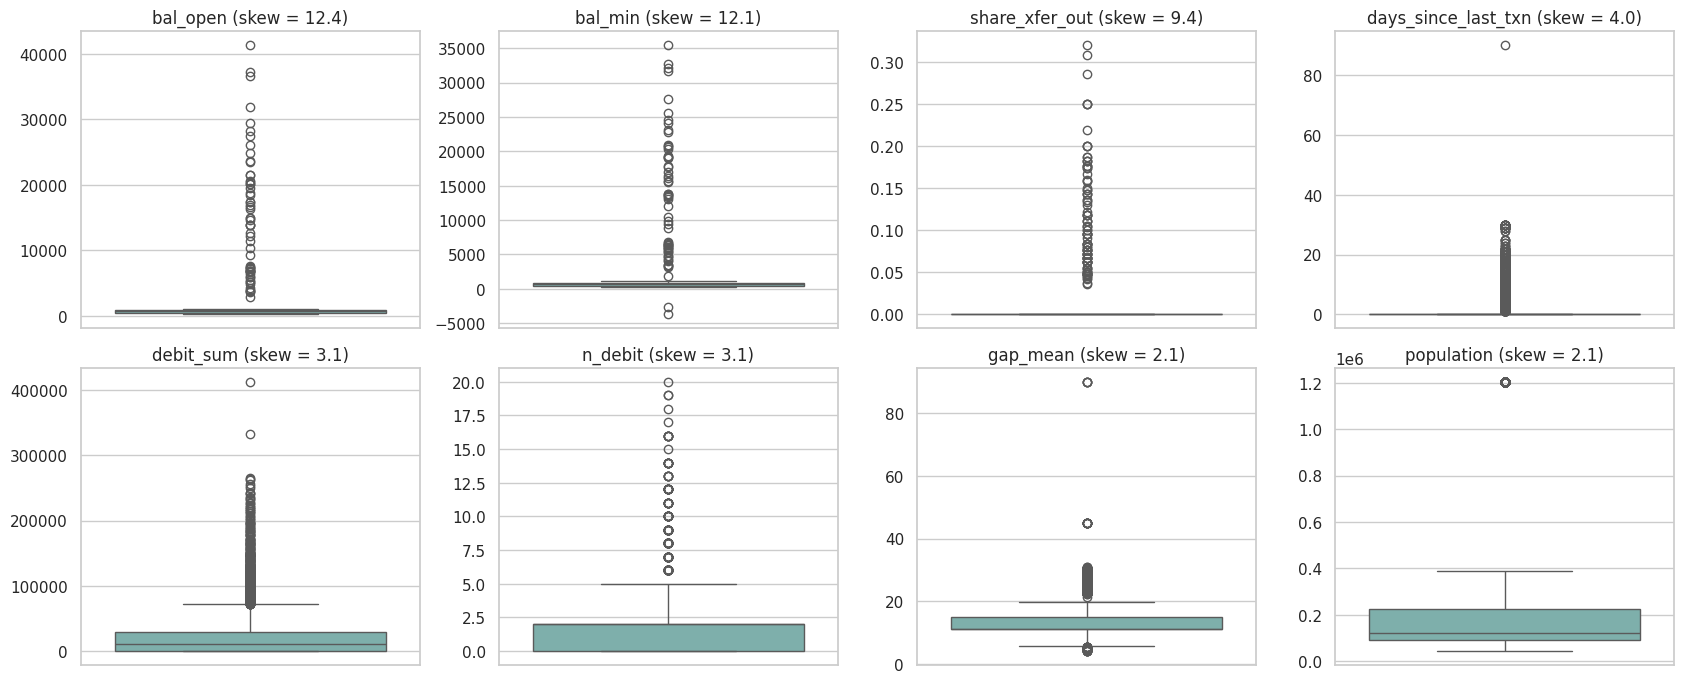

In [16]:
# Column groups used from here on
bin_cols = ["is_female", "has_disponent", "has_pension", "has_insurance", "has_household", "has_fees"]
cat_cols = ["frequency", "region"]
num_cols = [c for c in feature_cols if c not in bin_cols + cat_cols]

# Outliers
skewed = model_df[num_cols].skew().sort_values(key=abs, ascending=False).head(8)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (c, sk) in zip(axes.ravel(), skewed.items()):
    sns.boxplot(y=model_df[c], ax=ax, color="#76B7B2")
    ax.set(title=f"{c} (skew = {sk:.1f})", ylabel="")
plt.tight_layout(); plt.show()

**Observations.** The eight most right-skewed predictors (skewness between about 2 and 12) are balance levels (`bal_open`, `bal_min`), the share of transfers out, the number of days since the last transaction, debit totals and counts, the mean gap between transactions, and district population. Their boxplots show a compact box with a long tail of points beyond the upper whisker. These values are genuine banking behavior (large balances, overdrafts, very quiet accounts, Prague as a large district), so no rows are deleted and heavy-tailed predictors are instead compressed with a signed log transform in 4.3, which also handles negative balances.

**Feature behavior by class (all accounts)**

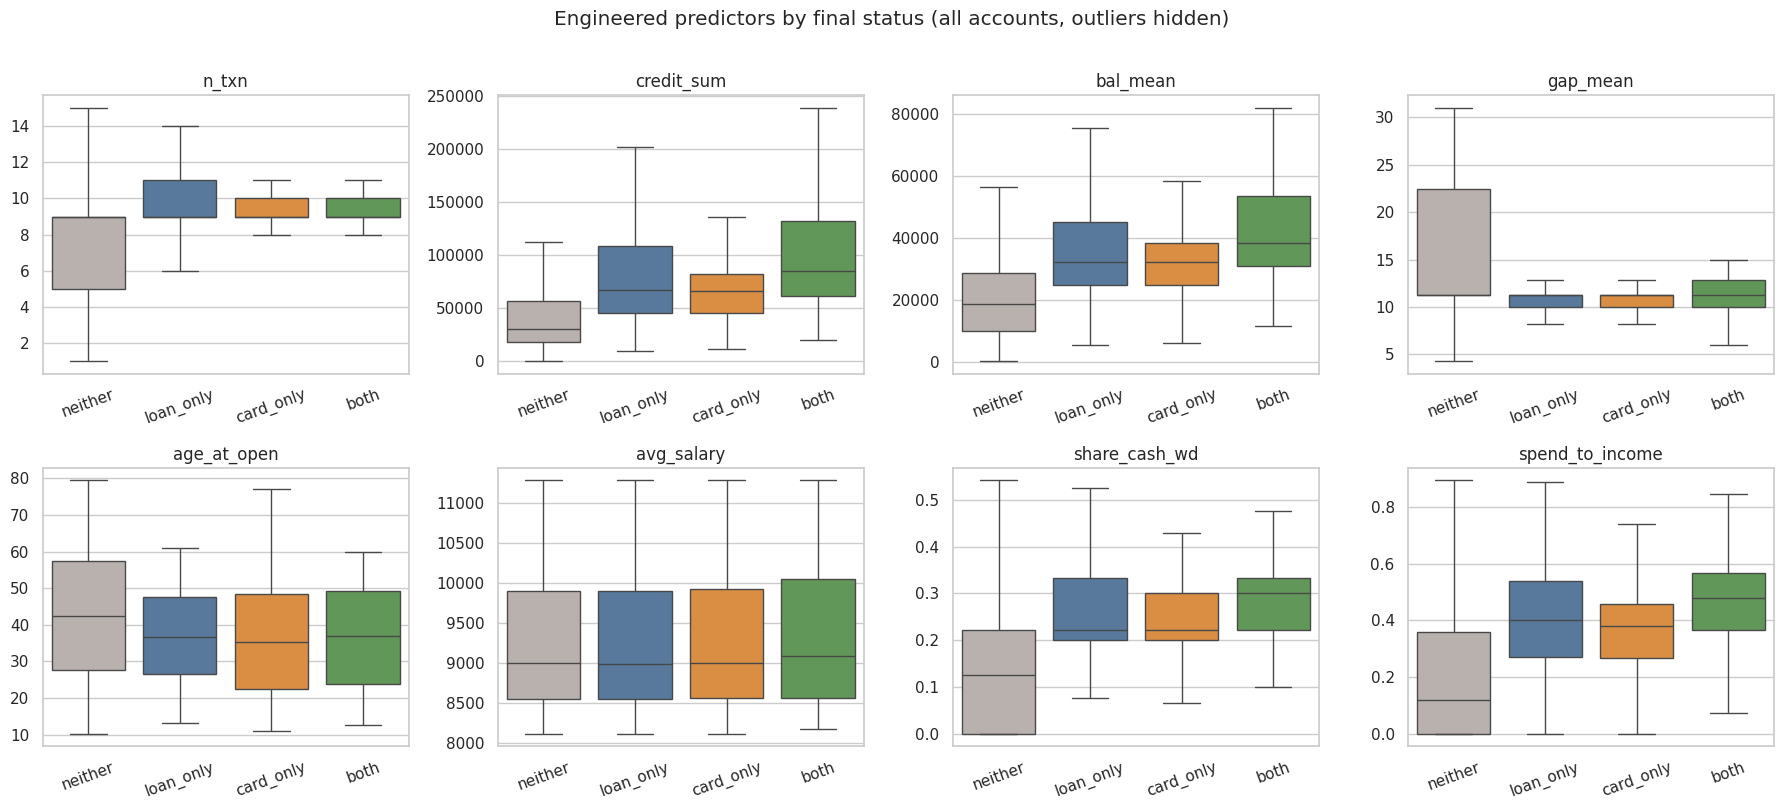

status4,neither,loan_only,card_only,both
n_txn,9.00,9.00,9.00,9.00
credit_sum,"30,799.25","67,081.55","66,018.90","84,687.90"
bal_mean,"18,738.40","32,203.86","32,281.19","38,562.04"
gap_mean,11.25,11.25,11.25,11.25
age_at_open,42.37,36.68,35.30,36.89
avg_salary,"8,991.00","8,980.00","8,991.00","9,084.50"
share_cash_wd,0.12,0.22,0.22,0.30
spend_to_income,0.12,0.40,0.38,0.48


status4,neither,loan_only,card_only,both
% of class with flag,,,,
has_pension,23.30,0.00,2.50,0.00
has_insurance,0.30,2.10,0.30,1.20
has_household,1.60,6.10,2.80,4.70
has_fees,4.00,10.50,6.80,10.00
has_disponent,19.70,21.30,15.90,21.20
is_female,49.20,51.40,46.80,50.00


In [17]:
show = ["n_txn", "credit_sum", "bal_mean", "gap_mean", "age_at_open", "avg_salary", "share_cash_wd", "spend_to_income"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(data=model_df, x="status4", y=c, order=CLASS_NAMES, showfliers=False, ax=ax,
                palette=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
    ax.set(title=c, xlabel="", ylabel=""); ax.tick_params(axis="x", rotation=20)
plt.suptitle("Engineered predictors by final status (all accounts, outliers hidden)", y=1.01); plt.tight_layout(); plt.show()

display(model_df.groupby("status4")[show].median().round(2).T)
flags = ["has_pension", "has_insurance", "has_household", "has_fees", "has_disponent", "is_female"]
(100 * model_df.groupby("status4")[flags].mean()).round(1).T.rename_axis("% of class with flag")

In [18]:
print("Does district context relate to adoption? % of accounts adopting any product, by quartile of each district variable")
adopted = model_df["status4"].ne("neither")
pd.concat({col: (adopted.groupby(pd.qcut(model_df[col], 4)).mean() * 100).round(1)
           for col in ["avg_salary", "unemp95", "urban_ratio"]},
          names=["variable", "quartile range"]).to_frame("% adopting any product")

Does district context relate to adoption? % of accounts adopting any product, by quartile of each district variable


% adopting any product
variable    quartile range                            
avg_salary  (8109.999, 8547.0]                   31.50
            (8547.0, 8991.0]                     30.90
            (8991.0, 9897.0]                     31.40
            (9897.0, 12541.0]                    31.00
unemp95     (0.289, 1.6]                         32.70
            (1.6, 2.77]                          29.10
            (2.77, 3.85]                         32.30
            (3.85, 7.34]                         30.20
urban_ratio (33.899, 52.7]                       32.10
            (52.7, 63.1]                         31.50
            (63.1, 85.6]                         29.60
            (85.6, 100.0]                        31.60

**Observations.** Eventual adopters look different from `neither` accounts in their first 90 days. Their median deposits are more than twice as large (credit_sum 66–85k vs 31k CZK), their typical average balance is higher (median of each account's mean balance: 32–39k vs 19k), they spend a larger share of what comes in (median spend-to-income 0.38–0.48 vs 0.12) and withdraw more cash (22–30% of transactions vs 12%). They are also younger (median age 35–37 vs 42). The median number of transactions (9) and the median gap between active days (11.25) are the same in every class; the difference is the spread. In the flag table, 23.3% of `neither` accounts receive a pension against none of the loan-only and both groups and 2.5% of card-only accounts, while insurance, household payments and fees are more common among adopters (for example fees: 6.8–10.5% vs 4.0%); gender and having a disponent differ little. District context, in the table above, shows little relation to adoption: 29–33% of accounts adopt something in every quartile of average salary, unemployment and urban ratio, and median district salary is nearly identical across classes (about 9,000 CZK).

**Feature correlation (all accounts)**

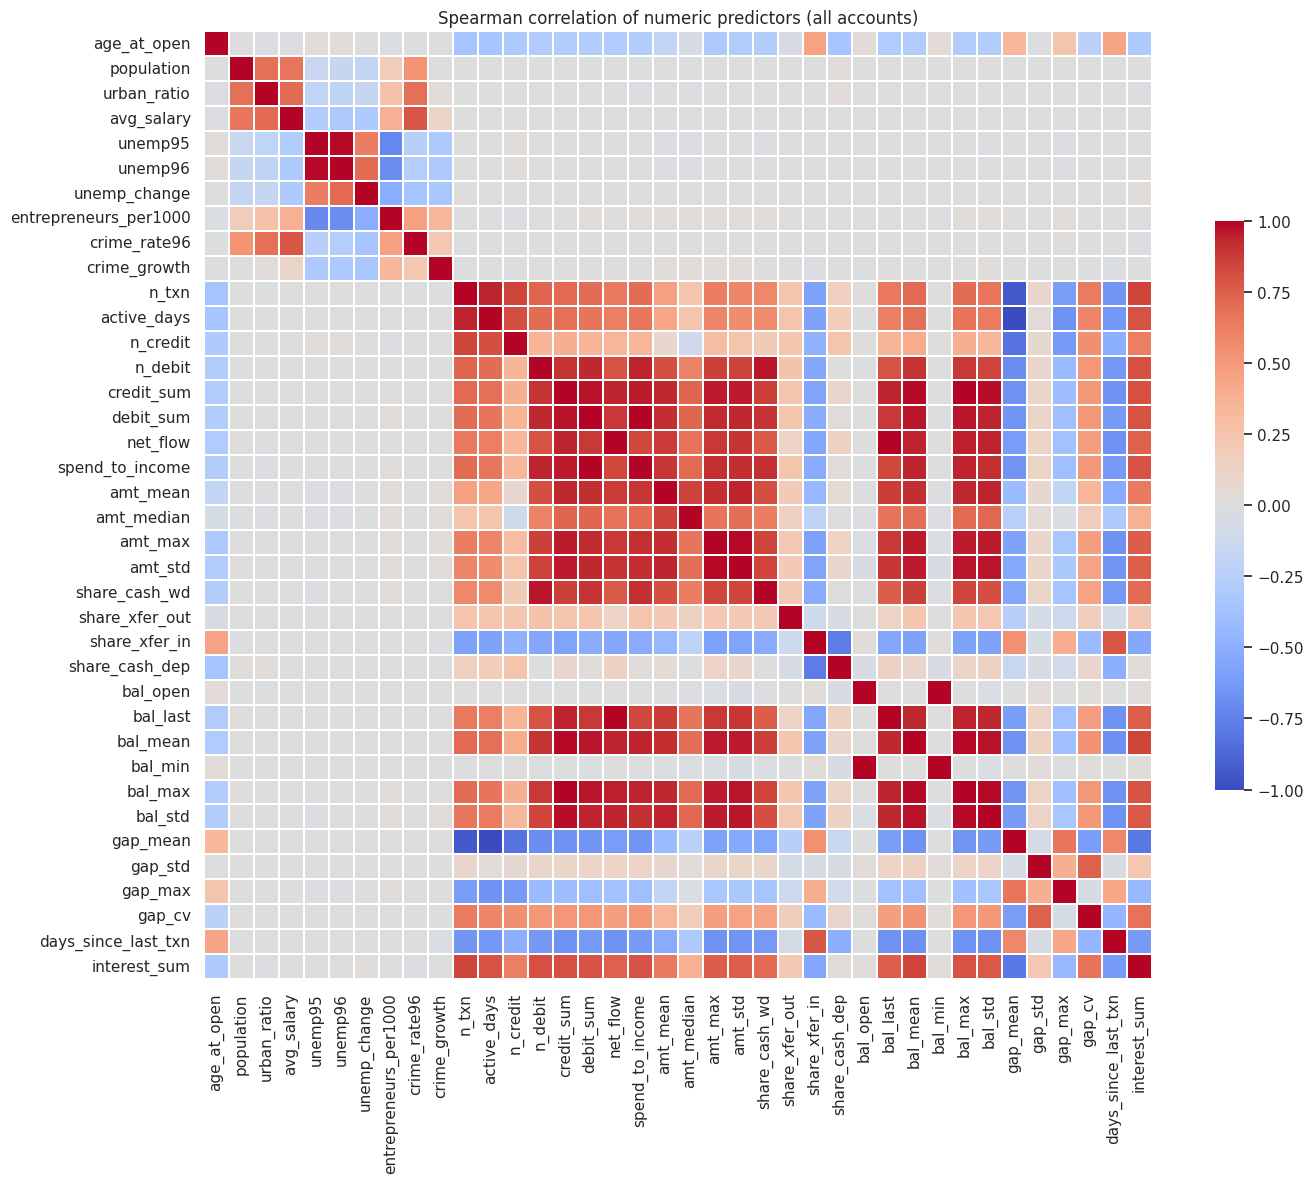

,count
predictor pairs,703
pairs with |rho| > 0.90,56


In [19]:
corr_all = model_df[num_cols].corr(method="spearman")
plt.figure(figsize=(15, 12))
sns.heatmap(corr_all, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .6}, linewidths=.2)
plt.title("Spearman correlation of numeric predictors (all accounts)"); plt.tight_layout(); plt.show()

upper = corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1))
pairs_all = upper.stack().dropna()
n_num = len(num_cols)
pd.Series({"predictor pairs": n_num * (n_num - 1) // 2,
           "pairs with |rho| > 0.90": int((pairs_all.abs() > 0.90).sum())}).to_frame("count")

**Observations.** 56 of 703 numeric predictor pairs have |rho| above 0.90, mainly among cash-flow and balance measures (which all reflect customer income level) and among activity counts. This redundancy is handled in Task 4.4, where the correlations are recomputed on the training set only and used to drop duplicate predictors.

#### Key findings from the EDA

The data are clean and structurally rich: 4,500 accounts, 1,056,320 transactions (1993–1998), each account holding at most one loan and one card. The target is **imbalanced**: 68.8% of accounts end with neither product, 16.0% with a card only, 11.4% with a loan only and just **3.8% (170 accounts) with both**, so accuracy alone will be misleading (always predicting "neither" scores about 70%) and macro-F1, per-class recall and one-vs-rest AUC will be needed. Timing is highly structured: no one adopts before day 102; loans arrive a median of 395 days after opening and **never later than day 697**, so loan incidence plateaus at about 16%, while cards start after day 203, arrive later (median 658 days) and keep accumulating (about 27% by five years). Card issuance also rises steeply with *calendar* time (1 card in 1993, 449 in 1998), so card adoption mixes account age with the bank's roll-out, and the 1997 test cohort sits in a period of rapid card growth. Observation ends in 1998, so "neither" means "not yet". Data-quality issues are minor: after recoding placeholders as true nulls there are 2,263,552 null cells, almost all of them structural and in the transaction and order tables (`operation` is blank exactly for interest credits, `bank` and `account` are filled only for transfers); the only genuine gaps are two district fields for district 69 (48 accounts). Amounts and balances are heavily right-skewed, and 2,999 negative-balance transactions on 288 accounts and 14 zero-amount transactions are genuine behavior. Most importantly, loan repayments (13,580 transactions) and card withdrawals (8,036) appear only *after* adoption, which proves that the full history leaks the answer and motivates the 90-day landmark.

Who adopts? Gender and region barely matter (65–72% "neither" in every region and 69% for both genders), whereas **age** (87% of customers aged 55+ end with neither product, versus 62–66% in every younger age band), **statement frequency** (50.5% of per-transaction and 42.5% of weekly-statement accounts end with neither product, versus 70.7% for monthly, though these groups are small at 93 and 240 accounts), and **early financial behavior** are informative. Over their first 90 days, eventual adopters have more than double the median deposits (66–85k vs 31k CZK) and a much higher typical average balance (median of 32–39k vs 19k CZK), spend a much larger share of what comes in (median spend-to-income 0.38–0.48 vs 0.12, cash-withdrawal share 22–30% vs 12%), and almost never receive a pension (0% of loan-only and both customers and 2.5% of card-only, versus 23.3% of "neither" accounts). District context shows little relation to adoption (29–33% adopt in every salary, unemployment and urban-ratio quartile). The adoption mix is stable across opening cohorts (66–71% neither), which supports a time-based split. These findings suggest that (i) macro-averaged metrics, class weights and per-class evaluation are needed; (ii) income/balance level, activity regularity, age and transaction mix should be the core predictors; (iii) many predictors will be redundant because they all reflect income level; and (iv) a model may partly learn "active, well-funded account" rather than "about to need credit", which the MTPP's timing information is meant to improve on.

### Task 4: Data Preprocessing

Before modeling, it's imperative to conduct necessary preprocessing on your dataset to ensure it's optimally formatted for machine learning algorithms. Data preprocessing aims to handle missing values, clean erroneous values, encode categorical features, and transform the data into a structure amenable to machine learning models.

#### 1. Initial Data Preparation

As you embark on preprocessing, consider that not every step may be necessary for your specific dataset. The choice of preprocessing steps should be informed by your data's characteristics, the requirements of your intended models, and your project's unique goals. Following are some aspects to consider for preprocessing your dataset:

- **Handling Missing Values**: Opt for an appropriate strategy such as deletion or imputation, considering the extent and nature of the missing data. *You can delete missing values before splitting the data, but more complex imputation methods are best calculated on the training set and then applied to the test set.*
  
- **Outlier Treatment**: After determining whether they represent true values or errors, decide on a treatment for outliers—this could involve deletion or correction.

  
- **Categorical Feature Encoding**: Based on your dataset, decide whether one-hot encoding or other methods (such as label encoding or ordinal encoding) are necessary for categorical features. For one-hot encoding, you can use `pd.get_dummies` in Pandas. *When performing feature encoding before data splitting, ensure that no new categories appear in the test set that were not present in the training set. Alternatively, you can split the data first, encode only the training set, and then apply the same encoding to the test set using the categories from the training set. For example, if using `pd.get_dummies`, you can use the `categories` parameter to ensure consistency between train and test encodings.*

**Plan for this section.** The per-account feature construction (district cleaning, 90-day window features and labels) was done in Section 3.9, because it uses *only that account's own transactions in its first 90 days* and does not borrow information across accounts. The cleaning decisions and predictor definitions are documented below. Everything that is *fitted* on data (imputation values, skew selection, encoders, scalers, correlation pruning) is done after the split, on the training set only (4.2-4.4).

#### 4.1 Initial data preparation: cleaning decisions and predictor definitions (implemented in 3.9)

**Cleaning decisions**

| Issue | Decision |
|---|---|
| `?` in district unemployment-1995 and crimes-1995 (district 69), blank `k_symbol` | Already recoded as true nulls in Task 3.3; district gaps are imputed with the **training-set median** later |
| Null `k_symbol` and `operation` in transactions | Treated as an explicit `none` category (interest credits have no operation) |
| `bank`, `account` (72–74% missing counterparty ids) | Dropped |
| Negative balances (overdrafts), huge transactions | **Kept**: they are real behavior; heavy tails are compressed with a signed log later instead of deleting rows |
| Post-adoption traces (`UVER`, `VYBER KARTOU`), loan `status`/`amount`/`duration`, card `type`, `order` table | Excluded; guaranteed absent by an assertion below |
| Customer history after day 90 | Excluded from predictors (landmark) |

**Engineered predictors (all from days 0–90 after opening)**

| Group | Features |
|---|---|
| Demographic | `age_at_open`, `is_female`, `has_disponent`, `frequency` (statement type) |
| District | `region`, `population`, `urban_ratio`, `avg_salary`, `unemp95`, `unemp96`, `unemp_change`, `entrepreneurs_per1000`, `crime_rate96` (per 1,000 residents), `crime_growth` |
| Activity | `n_txn`, `active_days`, `gap_mean`, `gap_std`, `gap_max`, `gap_cv` (inter-arrival times), `days_since_last_txn` |
| Cash flow | `n_credit`, `n_debit`, `credit_sum`, `debit_sum`, `net_flow`, `spend_to_income`, `amt_mean`, `amt_median`, `amt_max`, `amt_std` |
| Transaction mix | `share_cash_wd`, `share_xfer_out`, `share_xfer_in`, `share_cash_dep` |
| Balance | `bal_open`, `bal_last`, `bal_mean`, `bal_min`, `bal_max`, `bal_std` |
| Behavioral markers | `has_pension`, `has_insurance`, `has_household`, `has_fees`, `interest_sum` |

#### 2. Train-Test Split

It's advisable to split the data into training and test sets before applying any feature scaling, to avoid information leakage and ensure the test set accurately represents future unseen data. 

- **Data Split**: Use `train_test_split` to split your data. A common practice is to allocate approximately 70-80% of the data to the training set and the remainder to the testing set.
- **Random State**: Set a random state for reproducibility. This ensures you get the same split every time.
- **Time Series**: In the case of time series data, ensure to split the data based on time, avoiding randomization. This preserves the chronological order, which is vital for the integrity of time series analysis.
- **Sizing**: After splitting, verify the sizes of your train and test sets to ensure they are appropriate for your modeling needs.

#### 4.2 Time-based train-test split

Accounts are split by **opening date**: everything opened before 1 Jan 1997 is training, accounts opened in 1997 are the test set. This mirrors deployment (train on the past, score new customers) and, because the MTPP is a time-ordered model, avoids the optimism of a random split. The 1997 cohort is about 20% of accounts. Inside the training set I also define two **expanding-window validation folds** (train on earlier years, validate on the next year) for tuning later.

Two caveats are worth stating. (1) The 1997 cohort has the shortest follow-up (about 9-21 months after the landmark), so its "never adopted" labels are conservative, which is the realistic situation a bank faces for its newest customers. (2) Training labels are observed up to Dec 1998, i.e. after the test cohort's landmark dates; a live system would not have those labels yet. This is a small look-ahead that I accept for this project and will disclose in the final report.

In [20]:
train_mask = model_df["open_date"] < SPLIT_DATE
train_df, test_df = model_df[train_mask].copy(), model_df[~train_mask].copy()
assert train_df["open_date"].max() < test_df["open_date"].min()

split_tbl = pd.DataFrame({"accounts": [len(train_df), len(test_df)],
                          "share": [len(train_df) / len(model_df), len(test_df) / len(model_df)],
                          "opened from": [train_df["open_date"].min().date(), test_df["open_date"].min().date()],
                          "opened to": [train_df["open_date"].max().date(), test_df["open_date"].max().date()]},
                         index=["train (1993-1996)", "test (1997)"])
display(split_tbl)

dist_tbl = pd.concat({"train": train_df["status4"].value_counts(normalize=True) * 100,
                      "test": test_df["status4"].value_counts(normalize=True) * 100}, axis=1).reindex(CLASS_NAMES)
display(dist_tbl.round(1).rename_axis("class % "))
display(pd.Series({"majority-class baseline: test accuracy of always predicting 'neither' (%)": 100 * (test_df["status4"] == "neither").mean()}).round(1).to_frame("value"))

# expanding-window validation folds inside the training set (for hyperparameter tuning later)
cv_folds, cv_rows = [], []
for val_year in [1995, 1996]:
    tr_idx = train_df.index[train_df["open_year"] < val_year]
    va_idx = train_df.index[train_df["open_year"] == val_year]
    cv_folds.append((list(tr_idx), list(va_idx)))
    cv_rows.append({"validation year": val_year, "train accounts": len(tr_idx), "validation accounts": len(va_idx)})
pd.DataFrame(cv_rows).set_index("validation year")

,accounts,share,opened from,opened to
train (1993-1996),3602,0.80,1993-01-01,1996-12-30
test (1997),898,0.20,1997-01-01,1997-12-29


,train,test
class %,,
neither,68.40,70.30
loan_only,11.60,10.40
card_only,16.00,16.10
both,3.90,3.20


,value
majority-class baseline: test accuracy of always predicting 'neither' (%),70.30


,train accounts,validation accounts
validation year,,
1995,1578,661
1996,2239,1363


**Observations.** A model that always predicts `neither` reaches 70.3% accuracy on the 1997 test set, which is the baseline every model must beat. The two validation folds train on earlier years and validate on the next one (1,578 → 661 accounts, then 2,239 → 1,363).

**3. Feature Scaling**: 

- When evaluating the necessity of feature scaling, it is essential to consider the models you have chosen. Feature scaling significantly impacts the performance of certain models, while it may not be necessary for others.

   - Models that benefit from feature scaling: These models typically include those based on distance calculations and those that utilize gradient descent as their optimization algorithm. Specifically, models requiring feature scaling encompass:
     - K-Nearest Neighbors (KNN)
     - Support Vector Machines (SVM)
     - Linear Regression (when optimized using gradient descent)
     - Logistic Regression (when optimized using gradient descent)
     - Neural Networks

   - Models that do not require feature scaling: These models are unaffected by the scale of features due to the nature of their algorithms, hence do not necessitate feature scaling. These models include:

     - Decision Trees
     - Random Forests
     - Gradient Boosting Machines (e.g., XGBoost, LightGBM, CatBoost) 

- Type of Scaling: Decide on the type of scaling method. We have learnt Min-Max scaling and Standard scaling (Z-score normalization).


- Apply Scaling: We can use scalers like `StandardScaler` and `MinMaxScaler` provided in scikit-learn. Ensure you fit the scaler only on the training data and then transform both training and test datasets using the fitted scaler.


- Validate Scaling: After scaling, always verify the range of your features. Note: For MinMaxScaler, even though your training data is scaled to be between 0 and 1 after scaling, the test data may not be. This is expected, because we scale based on the statistics of the training data.

#### 4.3 Imputation, outlier compression, encoding and scaling (fitted on the training set only)

* **Missing values:** median imputation (district 69's two missing fields; undefined gap statistics for accounts with very few active days).
* **Outliers / skew:** predictors with |skew| > 1 *in the training set* get a signed log, `sign(x)·log(1+|x|)`, which also handles negative balances and net flow.
* **Encoding:** one-hot for `frequency` and `region` (`handle_unknown="ignore"` protects against unseen categories in later data).
* **Scaling:** standardization (z-score) for models that need it (logistic regression, Cox, neural networks); tree ensembles (Random Forest, XGBoost/LightGBM) do not need scaling, so I produce **two matrices**: `tree` (imputed + encoded, original units) and `scaled` (imputed + log + z-score + encoded).

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

signed_log = FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)), feature_names_out="one-to-one")

# skew is measured on TRAIN only
skew_train = train_df[num_cols].skew()
log_cols = skew_train[skew_train.abs() > 1].index.tolist()
lin_cols = [c for c in num_cols if c not in log_cols]
display(skew_train[log_cols].sort_values(key=abs, ascending=False).round(2).to_frame("training-set skew"))

ohe = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
tree_pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_cols),
                              ("bin", "passthrough", bin_cols), ("cat", ohe(), cat_cols)],
                             verbose_feature_names_out=False).set_output(transform="pandas")
scaled_pre = ColumnTransformer([
    ("log", Pipeline([("imp", SimpleImputer(strategy="median")), ("log", signed_log), ("sc", StandardScaler())]), log_cols),
    ("lin", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), lin_cols),
    ("bin", "passthrough", bin_cols), ("cat", ohe(), cat_cols)], verbose_feature_names_out=False).set_output(transform="pandas")

X_tr_raw, X_te_raw = train_df[feature_cols], test_df[feature_cols]
X_train_tree = tree_pre.fit_transform(X_tr_raw);   X_test_tree = tree_pre.transform(X_te_raw)
X_train_scaled = scaled_pre.fit_transform(X_tr_raw); X_test_scaled = scaled_pre.transform(X_te_raw)
y_train, y_test = train_df["y"], test_df["y"]

mats = {"X_train_tree": X_train_tree, "X_test_tree": X_test_tree, "X_train_scaled": X_train_scaled, "X_test_scaled": X_test_scaled}
display(pd.DataFrame({"rows": {k: v.shape[0] for k, v in mats.items()}, "columns": {k: v.shape[1] for k, v in mats.items()},
                      "remaining NaNs": {k: int(v.isna().sum().sum()) for k, v in mats.items()}}))
unseen_regions = sorted(set(X_te_raw["region"]) - set(X_tr_raw["region"]))
unseen_regions

,training-set skew
bal_open,12.79
bal_min,12.36
share_xfer_out,9.46
days_since_last_txn,4.06
debit_sum,3.16
n_debit,3.14
credit_sum,2.15
population,2.14
n_txn,1.85
interest_sum,1.80


,rows,columns,remaining NaNs
X_train_tree,3602,55,0
X_test_tree,898,55,0
X_train_scaled,3602,55,0
X_test_scaled,898,55,0


[]

**Observations.** 21 numeric predictors have a training-set skew above 1 (the most extreme are `bal_open` 12.8, `bal_min` 12.4 and `share_xfer_out` 9.5) and receive the signed log transform. All four matrices have 55 columns and no remaining nulls, and no region in the test set is unseen in training (the empty list).

,|mean| of test z-scores (cohort drift)
age_at_open,0.14
bal_min,0.07
bal_open,0.07
days_since_last_txn,0.06
gap_std,0.06
unemp_change,0.05
unemp95,0.05
unemp96,0.05
gap_max,0.05
entrepreneurs_per1000,0.04


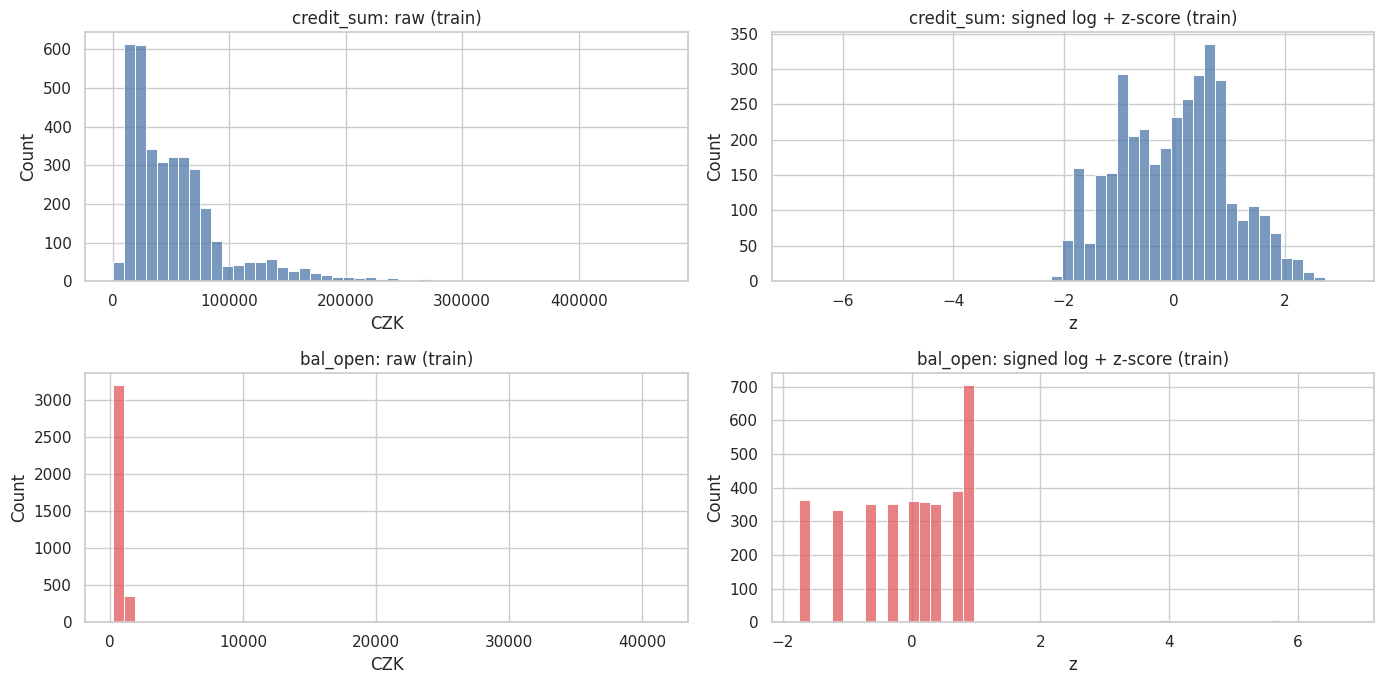

In [22]:
# Validate scaling: train is centered/scaled by construction; test is not (expected, it uses train statistics)
z_te = X_test_scaled[num_cols]
display(z_te.mean().abs().sort_values(ascending=False).head(10).round(2).to_frame("|mean| of test z-scores (cohort drift)"))

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
for r, (c, col) in enumerate(zip(["credit_sum", "bal_open"], ["#4C78A8", "#E15759"])):
    step = "signed log + z-score" if c in log_cols else "z-score only"
    sns.histplot(train_df[c], bins=50, ax=ax[r, 0], color=col); ax[r, 0].set(title=f"{c}: raw (train)", xlabel="CZK")
    sns.histplot(X_train_scaled[c], bins=50, ax=ax[r, 1], color=col); ax[r, 1].set(title=f"{c}: {step} (train)", xlabel="z")
plt.tight_layout(); plt.show()

**Observations.** The test set is scaled with training means and standard deviations, so any gap measures how far the 1997 cohort sits from the training cohorts. That gap is small: 37 of 38 predictors have an average test z-score within 0.1, and the largest is age_at_open at 0.14 (the 1997 customers are slightly older), followed by bal_min and bal_open at 0.07. The histograms show why the signed log was needed: credit_sum is strongly right-skewed in raw CZK (skew 2.15) and becomes almost symmetric after transformation, and so does bal_open. Together, these checks suggest that the 1997 cohort looks similar to earlier cohorts on the engineered predictors, so a model trained on 1993–1996 accounts is not being applied to a very different population.

**4. Feature Engineering (Optional)：**
Feature engineering is an optional step and should be considered only if your dataset requires it. The goal of this step is to enhance the dataset by creating new, more informative features or by selecting the most relevant features for your model. Feature engineering is usually performed after the train-test split to avoid information leakage and ensure that the test set remains an unbiased representation of unseen data.

- **Feature Construction**:create new features based on existing ones. Techniques like Principal Component Analysis (PCA) or other dimensionality reduction methods can be useful to simplify high-dimensional datasets. We will cover PCA in more detail in Week 7.

- **Feature Selection**: perform feature selection to eliminate redundant or irrelevant features. This can be done using methods such as correlation analysis or model-based feature importance (e.g., using feature importance from decision trees or Lasso regression). This helps improve model performance and reduces the risk of overfitting.

#### 4.4 Feature engineering and selection (training set only)

Most feature *construction* happened in Section 3.9 (windowed behavior features), where the engineered predictors were also explored descriptively on all accounts. Here I (a) remove near-duplicate predictors using the correlation matrix", (b) preview which predictors carry signal with two model-based rankings, (c) build the event-sequence dataset for the MTPP and (d) save the outputs. Everything below uses `train_df` only, so the 1997 test cohort stays untouched.

**(a) Feature correlation and redundancy**

The correlation heatmap for all accounts is in Section 3.9. Here the same Spearman correlations are recomputed on the training set only to decide which predictors to drop. Many engineered predictors measure the same thing (customer income and balance level), and highly correlated predictors add little new information while destabilizing logistic regression and Cox coefficients (tree models are less affected). For every pair of predictors with |correlation| above 0.90, we drop the one that tells us less about the 4-class target, measured by mutual information (how much knowing the predictor reduces uncertainty about the class).

In [23]:
from sklearn.feature_selection import mutual_info_classif

corr = X_train_scaled[num_cols].corr(method="spearman").abs()      # absolute Spearman correlations (training set)
mi = pd.Series(mutual_info_classif(X_train_tree[num_cols], y_train, random_state=RANDOM_STATE), index=num_cols)

# 1) every pair of predictors with correlation above 0.90, strongest first
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna()
pairs = pairs[pairs > 0.90].sort_values(ascending=False)

# 2) for each pair, drop the predictor that tells us less about the target (lower mutual information)
drop_corr = []
for (a, b), rho in pairs.items():
    if a in drop_corr or b in drop_corr:
        continue                                   # one of the two is already removed, so this pair is already resolved
    drop_corr.append(a if mi[a] < mi[b] else b)
drop_corr = sorted(drop_corr)

# 3) show each dropped predictor next to the kept predictor it is most correlated with
kept_num = [c for c in num_cols if c not in drop_corr]
summary = pd.DataFrame({"most correlated kept predictor": [corr.loc[d, kept_num].idxmax() for d in drop_corr],
                        "|rho|": [corr.loc[d, kept_num].max() for d in drop_corr]}, index=drop_corr)
display(summary.sort_values("|rho|", ascending=False).rename_axis("dropped predictor"))

final_cols_tree = [c for c in X_train_tree.columns if c not in drop_corr]
final_cols_scaled = [c for c in X_train_scaled.columns if c not in drop_corr]
X_train_tree_f, X_test_tree_f = X_train_tree[final_cols_tree], X_test_tree[final_cols_tree]
X_train_scaled_f, X_test_scaled_f = X_train_scaled[final_cols_scaled], X_test_scaled[final_cols_scaled]
print(f"Predictors: {X_train_tree.shape[1]} -> {X_train_tree_f.shape[1]} after redundancy pruning ({len(drop_corr)} dropped)")

,most correlated kept predictor,|rho|
dropped predictor,,
bal_min,bal_open,1.00
active_days,gap_mean,1.00
credit_sum,bal_mean,0.99
bal_max,bal_mean,0.99
unemp96,unemp95,0.98
bal_std,bal_mean,0.97
debit_sum,bal_mean,0.97
n_debit,share_cash_wd,0.97
amt_std,bal_mean,0.96


Predictors: 55 -> 40 after redundancy pruning (15 dropped)


**Observations.** Fifteen predictors were dropped leaving 40 columns.

**(b) Which predictors carry signal?** Mutual information and Random Forest impurity importance are computed on the pruned training set. These rankings guide model building in Week 7; they are not final feature selection.

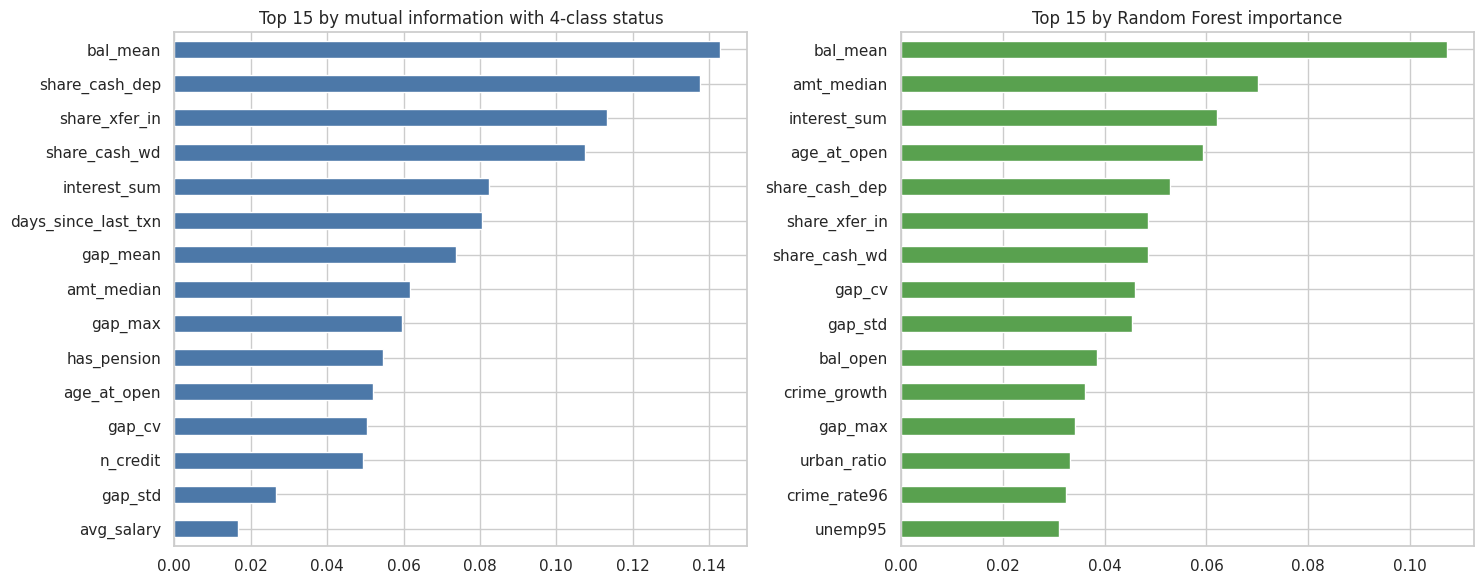

,in both top-10 rankings
0,amt_median
1,bal_mean
2,interest_sum
3,share_cash_dep
4,share_cash_wd
5,share_xfer_in


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

discrete = np.array([c in bin_cols or c.startswith(("frequency_", "region_")) for c in X_train_tree_f.columns])
mi = pd.Series(mutual_info_classif(X_train_tree_f, y_train, discrete_features=discrete, random_state=RANDOM_STATE), index=X_train_tree_f.columns)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_tree_f, y_train)
imp = pd.Series(rf.feature_importances_, index=X_train_tree_f.columns)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
mi.sort_values().tail(15).plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Top 15 by mutual information with 4-class status")
imp.sort_values().tail(15).plot.barh(ax=ax[1], color="#59A14F"); ax[1].set_title("Top 15 by Random Forest importance")
plt.tight_layout(); plt.show()
pd.Series(sorted(set(mi.nlargest(10).index) & set(imp.nlargest(10).index)), name="in both top-10 rankings").to_frame()

**Observations.** Mean balance ranks first under both methods, and six predictors are in the top 10 of both rankings: `bal_mean`, `amt_median`, `interest_sum`, `share_cash_dep`, `share_cash_wd` and `share_xfer_in`. Age and the inter-arrival variability (`gap_cv`, `gap_std`) rank high in the Random Forest list, while district variables appear lower in the importance ranking.

**(c) Transaction sequences for the MTPP.** The RMTPP consumes the raw event stream rather than aggregates. For each account I store its 90-day window as an array of events with columns `[t_day, dt_days, log1p_amount, type_id, operation_id, ksymbol_id]`, using a fixed, data-independent vocabulary. The same labels and split apply. Sequences are standardized later inside the model data loader (training statistics only).

Accounts with sequences: 4500 | events per account:


,count,mean,std,min,25%,50%,75%,max
0,"4,500.00",8.65,3.57,1.00,7.00,9.00,10.00,33.00


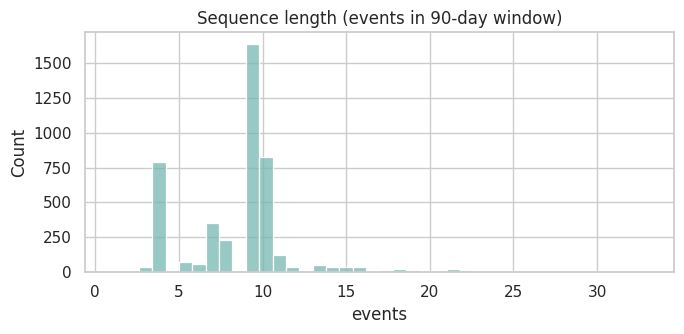

,t_day,dt_days,log1p_amount,type_id,operation_id,ksymbol_id
first events of account 576,,,,,,
0,0.00,0.00,6.80,0.00,1.00,0.00
1,10.00,10.00,8.73,0.00,4.00,4.00
2,30.00,20.00,3.05,0.00,0.00,1.00
3,41.00,11.00,8.73,0.00,4.00,4.00
4,58.00,17.00,3.42,0.00,0.00,1.00
5,69.00,11.00,8.73,0.00,4.00,4.00


In [25]:
import json, pickle

VOCAB = {"type": {"PRIJEM": 0, "VYDAJ": 1, "VYBER": 2},
         "operation": {"none": 0, "VKLAD": 1, "VYBER": 2, "PREVOD NA UCET": 3, "PREVOD Z UCTU": 4, "VYBER KARTOU": 5},
         "ksymbol": {"none": 0, "UROK": 1, "SLUZBY": 2, "SIPO": 3, "DUCHOD": 4, "POJISTNE": 5, "SANKC. UROK": 6, "UVER": 7}}
SEQ_COLS = ["t_day", "dt_days", "log1p_amount", "type_id", "operation_id", "ksymbol_id"]

w = win.copy()
w["dt_days"] = w.groupby("account_id")["day"].diff().fillna(0)
seq_arr = np.column_stack([w["day"], w["dt_days"], np.log1p(w["amount"]),
                           w["type"].map(VOCAB["type"]), w["op"].map(VOCAB["operation"]), w["ksym"].map(VOCAB["ksymbol"])]).astype("float32")
assert not np.isnan(seq_arr).any(), "unmapped category in vocabulary"
acc_ids = w["account_id"].to_numpy()
bounds = np.flatnonzero(np.r_[True, acc_ids[1:] != acc_ids[:-1], True])
sequences = {int(acc_ids[s]): seq_arr[s:e] for s, e in zip(bounds[:-1], bounds[1:])}

seq_len = pd.Series({k: len(v) for k, v in sequences.items()})
print("Accounts with sequences:", len(sequences), "| events per account:"); display(seq_len.describe().to_frame().T)
plt.figure(figsize=(7, 3.5)); sns.histplot(seq_len, bins=40, color="#76B7B2"); plt.title("Sequence length (events in 90-day window)"); plt.xlabel("events"); plt.tight_layout(); plt.show()
ex = train_df.index[0]
display(pd.DataFrame(sequences[ex][:6], columns=SEQ_COLS).round(2).rename_axis(f"first events of account {ex}"))

**(d) Save the processed data** for Weeks 7-8 (models, tuning, final evaluation).

In [26]:
lab_cols = ["y", "status4", "first_event", "event_observed", "t_from_landmark", "open_date"]
X_train_tree_f.to_csv(OUT_DIR / "X_train_tree.csv");     X_test_tree_f.to_csv(OUT_DIR / "X_test_tree.csv")
X_train_scaled_f.to_csv(OUT_DIR / "X_train_scaled.csv"); X_test_scaled_f.to_csv(OUT_DIR / "X_test_scaled.csv")
train_df[lab_cols].to_csv(OUT_DIR / "labels_train.csv"); test_df[lab_cols].to_csv(OUT_DIR / "labels_test.csv")

with open(OUT_DIR / "sequences.pkl", "wb") as f:
    pickle.dump({"train": {i: sequences[i] for i in train_df.index}, "test": {i: sequences[i] for i in test_df.index},
                 "columns": SEQ_COLS, "vocab": VOCAB, "landmark_days": LANDMARK_DAYS}, f)

pd.DataFrame({"size (KB)": {p.name: round(p.stat().st_size / 1024) for p in sorted(OUT_DIR.iterdir())}}).rename_axis(f"saved in {OUT_DIR}/")

,size (KB)
saved in processed/,
X_test_scaled.csv,453
X_test_tree.csv,256
X_train_scaled.csv,1813
X_train_tree.csv,1029
labels_test.csv,33
labels_train.csv,133
preprocessing_info.json,34
sequences.pkl,1068


<span style="color:GREEN">**After completing the preprocessing steps, write 1-2 paragraphs summarizing the actions you took and the rationale behind them. This summary should explain how each preprocessing step was intended to improve the compatibility of the dataset with your modeling strategy and enable achieving your project goals.**</span>

#### Summary of preprocessing actions and rationale

The raw tables were turned into one row per account observed at a fixed 90-day landmark after opening. Predictors use only transactions up to that day (38,935 of 1.06 million transactions), which removes the leakage found in the EDA: loan repayments, card withdrawals, loan terms/status, card type and the undated `order` table were excluded, and assertions confirm that nobody adopts before the landmark. I built 46 predictors in seven groups (demographics, district context, activity and inter-arrival timing, cash flow, transaction mix, balances, behavioral markers), plus a parallel event-sequence dataset of the same 90-day windows for the RMTPP. The target is the four-class final status (`neither`, `loan_only`, `card_only`, `both`), with the first-adoption type, time to it and censoring flag retained for the survival and MTPP models. Data cleaning included the following steps: (1)placeholder text (`?`, blanks) was recoded as true nulls, (2)null `k_symbol`/`operation` became an explicit `none` category, and (3)sparse counterpart identifiers were dropped. Outliers were kept because large deposits and overdrafts are real behavior, and were compressed instead.

The data were split by time: 3,602 accounts opened in 1993–1996 for training and 898 accounts opened in 1997 for testing (class mix 68.4/11.6/16.0/3.9% vs 70.3/10.4/16.1/3.2%, majority-class test accuracy 70.3%), with two expanding-window validation folds defined inside the training data. All fitted steps used the training set only: median imputation (158 missing cells: 48 accounts in district 69 plus a handful of accounts with too few active days), a signed-log transform for 21 heavy-tailed predictors (|skew| > 1), one-hot encoding of statement frequency and region, and standardization. Two matrices were produced, an unscaled one for tree ensembles and a scaled one for logistic regression, Cox models and neural networks. Correlation analysis showed that most cash-flow and balance features move together (one "income level" factor), so for each highly correlated pair (|rho| > 0.90) I dropped the predictor that was less informative about the target, removing 15 predictors and leaving 40 columns. Mutual information and a Random Forest agree that mean balance, median transaction amount, interest earned and the cash-deposit, cash-withdrawal and transfer-in mix are the strongest signals. We noted that district variables take only 77 distinct values and can act as district identifiers, so they should be watched for overfitting. Remaining limitations are the small sample (only 29 `both` accounts in the test set, so per-class estimates will be noisy), the shorter follow-up of the 1997 cohort, the calendar-driven growth in card issuance, and a small look-ahead because training labels extend to Dec 1998.

*Data preprocessing contains many potential steps. Since this is our first machine learning project exercise, we've learnt and outlined some of the commonly used procedures. However, many other steps may vary based on the project, data, and specific objectives, such as dimensionality reduction via PCA, handling class imbalance, text data preprocessing, time series transformation, etc. What we covered so far gets you started, but you will expand your preprocessing skills over time as you work on diverse real-world applications.*

## Part B. This week (Week 7): model selection, training and initial evaluation

### Task 0 (revised): Fixed-horizon target, time-based split and re-run of the preprocessing

**Target.** Week 6 labelled an account by whether it *ever* adopted a product before the end of the data (31 Dec 1998). Feedback on that notebook pointed out that this label is not comparable across cohorts: a 1993 account was watched for about five years, a 1997 account for one to two. The primary target is now a **fixed-horizon label**: whether the account adopted a loan and/or a card **within 365 days of its 90-day landmark** (about 15 months after opening), the same window for every account. Accounts watched for fewer than 365 days after the landmark (opened after 2 Oct 1997, 197 accounts) cannot be labelled and are excluded, which leaves **4,303 accounts**. The Week 6 end-of-data label is kept as a sensitivity analysis at the end of Task 2.

**Primary split: time-based, as in Week 6.** Accounts opened **before 1997 are the training set (3,602 accounts, 19 with `both`)** and **1997 accounts are the test set (701 accounts, 14 with `both`)**, which mimics scoring new customers with a model built on the past. All *fitted* preprocessing steps (median imputation, signed-log selection, standardization, one-hot encoding and the correlation-based pruning) are **re-fitted on the training accounts only**; the test rows are only transformed. For tuning in the next stage there are two expanding-window folds inside the training set (train on 1993-94 and validate on 1995, train on 1993-95 and validate on 1996).

**Secondary split: random stratified 80/20** of the same 4,303 accounts (stratified on the four-class label, `random_state=42`; 3,442 train and 861 test accounts). The same models are re-fitted on it at the end of Task 2 to show how much a random split would flatter the results.

**Two clocks per account.** Loans and cards are *not* competing risks: a customer who takes a loan can still take a card later (170 accounts hold both by the end of the data). Each product therefore gets its own time-to-event target, measured from the landmark and censored at the end of observation (31 Dec 1998) if the product is never adopted: `t_loan`, `e_loan`, `t_card`, `e_card`. The survival models use these full time-to-event targets, and their prediction is converted to the same fixed-horizon classes.

**Caveats.** (1) The 1997 cohort adopts faster than earlier ones (figure below): 23.5% of the test accounts adopt a product within 365 days against 12.5% of the training accounts, so the class priors shift between train and test. (2) Training labels and survival targets of late-1996 accounts are resolved after some 1997 landmarks, a mild look-ahead already noted in Week 6; test labels are never used in training. (3) `both` is rare at this horizon (19 training and 14 test accounts), so macro-F1 is noisy.

In [3]:
# After Part A is finished: free its objects (raw tables, figures). Part B rebuilds everything it needs from the raw files.
import matplotlib.pyplot as plt; plt.close("all")
%reset -f

import warnings, json, pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
DATA_DIR = Path("berka")                 # the 8 Berka CSV files
OUT_DIR = Path("processed_h365")         # outputs of this notebook (separate from the Week 6 'processed/' folder)
OUT_DIR.mkdir(exist_ok=True)

LANDMARK_DAYS = 90                       # prediction time = account opening + 90 days
OBS_END = pd.Timestamp("1998-12-31")     # end of observation (right-censoring date)
TEMPORAL_SPLIT_DATE = pd.Timestamp("1997-01-01")   # used later for the temporal robustness check
HORIZON_DAYS = 365                       # fixed prediction horizon: adoption within N days after the 90-day landmark
CLASS_NAMES = ["neither", "loan_only", "card_only", "both"]

Accounts observed for the full 365-day horizon: 4,303 of 4,500 (excluded: opened after 1997-10-02)
Modelling table: 4,303 accounts x 46 predictors | sequences: 4,500


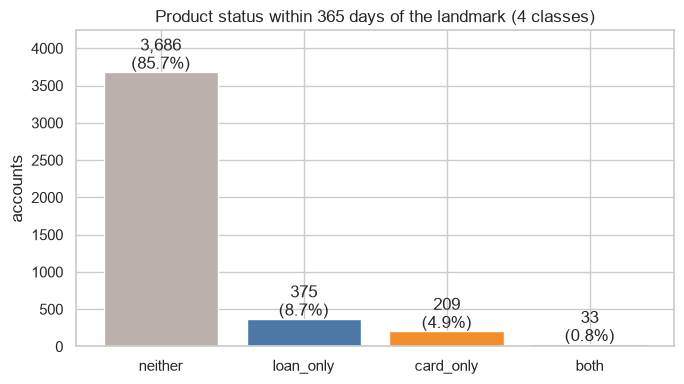

In [4]:
# ---- 1. load raw tables (same cleaning rules as Week 6)
def read_table(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", sep=";", low_memory=False)

account, card, client, disp, district, loan, trans = (read_table(n) for n in
    ["account", "card", "client", "disp", "district", "loan", "trans"])
to_date = lambda s: pd.to_datetime(s.astype(str).str[:6], format="%y%m%d")
account["date"], loan["date"] = to_date(account["date"]), to_date(loan["date"])
card["issued"], trans["date"] = to_date(card["issued"]), to_date(trans["date"])
for df in [account, card, client, disp, district, loan, trans]:          # "?" and blanks -> real nulls
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip().replace({"": np.nan, "?": np.nan})

# ---- 2. targets: four-class status + one survival clock per product
acct = account.rename(columns={"date": "open_date"}).set_index("account_id")
loan_first = loan.groupby("account_id")["date"].min().rename("loan_date")
card_first = (card.merge(disp[["disp_id", "account_id"]], on="disp_id")
                  .groupby("account_id")["issued"].min().rename("card_date"))
acct = acct.join([loan_first, card_first])
acct["has_loan"], acct["has_card"] = acct["loan_date"].notna(), acct["card_date"].notna()
acct["y_end"] = acct["has_loan"].astype(int) + 2 * acct["has_card"].astype(int)   # sensitivity label: adopted at any time before the end of the data
acct["status_end"] = pd.Categorical(acct["y_end"].map(dict(enumerate(CLASS_NAMES))), categories=CLASS_NAMES)
acct["open_year"] = acct["open_date"].dt.year
acct["follow_up"] = (OBS_END - acct["open_date"]).dt.days - LANDMARK_DAYS         # landmark -> end of observation
for p in ["loan", "card"]:
    t = (acct[f"{p}_date"] - acct["open_date"]).dt.days - LANDMARK_DAYS
    acct[f"t_{p}"] = t.where(acct[f"has_{p}"], acct["follow_up"])                 # censored at end of observation
    acct[f"e_{p}"] = acct[f"has_{p}"].astype(int)
    assert acct.loc[acct[f"has_{p}"], f"t_{p}"].min() > 0, "adoption before landmark"

# fixed-horizon label (primary target): adopted within HORIZON_DAYS of the landmark, the same window for every account
for p in ["loan", "card"]:
    acct[f"{p}_H"] = ((acct[f"e_{p}"] == 1) & (acct[f"t_{p}"] <= HORIZON_DAYS)).astype(int)
acct["y"] = acct["loan_H"] + 2 * acct["card_H"]                                   # 0 neither, 1 loan, 2 card, 3 both
acct["status4"] = pd.Categorical(acct["y"].map(dict(enumerate(CLASS_NAMES))), categories=CLASS_NAMES)
acct["full_window"] = acct["follow_up"] >= HORIZON_DAYS                           # the label is only defined if the whole horizon was observable

# ---- 3. static predictors (owner age/gender, statement frequency, district context)
owner = disp[disp["type"] == "OWNER"].merge(client, on="client_id").set_index("account_id")
b = owner["birth_number"].astype(int); month = (b // 100) % 100
owner["is_female"] = (month > 50).astype(int)
owner["birth_date"] = pd.to_datetime({"year": 1900 + b // 10000, "month": np.where(month > 50, month - 50, month), "day": b % 100})
acct = acct.join(owner[["is_female", "birth_date"]])
acct["age_at_open"] = (acct["open_date"] - acct["birth_date"]).dt.days / 365.25
acct["has_disponent"] = (disp.groupby("account_id").size() > 1).astype(int).reindex(acct.index)
acct["frequency"] = acct["frequency"].map({"POPLATEK MESICNE": "monthly", "POPLATEK TYDNE": "weekly", "POPLATEK PO OBRATU": "per_transaction"})
dist = district.rename(columns={"A1": "district_id", "A3": "region", "A4": "population", "A10": "urban_ratio", "A11": "avg_salary",
    "A12": "unemp95", "A13": "unemp96", "A14": "entrepreneurs_per1000", "A15": "crimes95", "A16": "crimes96"})
for c in ["unemp95", "crimes95"]:
    dist[c] = pd.to_numeric(dist[c])
dist["unemp_change"] = dist["unemp96"] - dist["unemp95"]
dist["crime_rate96"] = dist["crimes96"] / dist["population"] * 1000
dist["crime_growth"] = dist["crimes96"] / dist["crimes95"] - 1
dist_cols = ["population", "urban_ratio", "avg_salary", "unemp95", "unemp96", "unemp_change", "entrepreneurs_per1000", "crime_rate96", "crime_growth"]
acct = acct.join(dist.set_index("district_id")[["region"] + dist_cols], on="district_id")

# ---- 4. behavioural predictors from the first 90 days only (identical to Week 6)
def build_window_features(trans, acct, landmark_days=LANDMARK_DAYS):
    t = trans.merge(acct[["open_date"]], left_on="account_id", right_index=True)
    t["day"] = (t["date"] - t["open_date"]).dt.days
    w = t[t["day"] <= landmark_days].sort_values(["account_id", "date", "trans_id"]).copy()
    w["is_credit"] = w["type"].eq("PRIJEM")
    w["ksym"] = w["k_symbol"].fillna("").str.strip().replace("", "none")
    w["op"] = w["operation"].fillna("none")
    g = w.groupby("account_id")
    f = pd.DataFrame(index=acct.index)
    f["n_txn"] = g.size(); f["active_days"] = g["date"].nunique()
    cred, deb = w[w["is_credit"]].groupby("account_id")["amount"], w[~w["is_credit"]].groupby("account_id")["amount"]
    f["n_credit"], f["n_debit"], f["credit_sum"], f["debit_sum"] = cred.size(), deb.size(), cred.sum(), deb.sum()
    f[["n_credit", "n_debit", "credit_sum", "debit_sum"]] = f[["n_credit", "n_debit", "credit_sum", "debit_sum"]].fillna(0)
    f["net_flow"] = f["credit_sum"] - f["debit_sum"]
    f["spend_to_income"] = f["debit_sum"] / f["credit_sum"].replace(0, np.nan)
    f["amt_mean"], f["amt_median"], f["amt_max"], f["amt_std"] = g["amount"].mean(), g["amount"].median(), g["amount"].max(), g["amount"].std()
    for name, op in {"share_cash_wd": "VYBER", "share_xfer_out": "PREVOD NA UCET", "share_xfer_in": "PREVOD Z UCTU", "share_cash_dep": "VKLAD"}.items():
        f[name] = w["op"].eq(op).groupby(w["account_id"]).mean()
    f["bal_open"], f["bal_last"] = g["balance"].first(), g["balance"].last()
    f["bal_mean"], f["bal_min"], f["bal_max"], f["bal_std"] = g["balance"].mean(), g["balance"].min(), g["balance"].max(), g["balance"].std()
    d = w.drop_duplicates(["account_id", "date"]).copy()
    d["gap"] = d.groupby("account_id")["date"].diff().dt.days
    gg = d.groupby("account_id")["gap"]
    f["gap_mean"], f["gap_std"], f["gap_max"] = gg.mean(), gg.std(), gg.max()
    f["gap_cv"] = f["gap_std"] / f["gap_mean"].replace(0, np.nan)
    f["days_since_last_txn"] = landmark_days - d.groupby("account_id")["day"].max()
    for name, k in {"has_pension": "DUCHOD", "has_insurance": "POJISTNE", "has_household": "SIPO", "has_fees": "SLUZBY"}.items():
        f[name] = w["ksym"].eq(k).groupby(w["account_id"]).any().astype(int).fillna(0).astype(int)
    f["interest_sum"] = w[w["ksym"] == "UROK"].groupby("account_id")["amount"].sum().reindex(f.index).fillna(0)
    return f, w

win_features, win = build_window_features(trans, acct)
assert (win["ksym"] == "UVER").sum() == 0 and (win["op"] == "VYBER KARTOU").sum() == 0, "post-adoption traces in window"

# ---- 5. event sequences for the GRU (same layout as Week 6)
VOCAB = {"type": {"PRIJEM": 0, "VYDAJ": 1, "VYBER": 2},
         "operation": {"none": 0, "VKLAD": 1, "VYBER": 2, "PREVOD NA UCET": 3, "PREVOD Z UCTU": 4, "VYBER KARTOU": 5},
         "ksymbol": {"none": 0, "UROK": 1, "SLUZBY": 2, "SIPO": 3, "DUCHOD": 4, "POJISTNE": 5, "SANKC. UROK": 6, "UVER": 7}}
SEQ_COLS = ["t_day", "dt_days", "log1p_amount", "type_id", "operation_id", "ksymbol_id"]
w = win.copy(); w["dt_days"] = w.groupby("account_id")["day"].diff().fillna(0)
seq_arr = np.column_stack([w["day"], w["dt_days"], np.log1p(w["amount"]), w["type"].map(VOCAB["type"]),
                           w["op"].map(VOCAB["operation"]), w["ksym"].map(VOCAB["ksymbol"])]).astype("float32")
assert not np.isnan(seq_arr).any()
ids_ = w["account_id"].to_numpy(); bounds = np.flatnonzero(np.r_[True, ids_[1:] != ids_[:-1], True])
sequences = {int(ids_[s]): seq_arr[s:e] for s, e in zip(bounds[:-1], bounds[1:])}

# free the raw transaction table and intermediates (about 1 million rows), which are no longer needed once features and sequences exist
import gc
del trans, win, w, seq_arr, ids_, bounds; gc.collect()

# ---- 6. one modelling table
STATIC_BASE = ["age_at_open", "is_female", "has_disponent", "frequency", "region"] + dist_cols
target_cols = ["y", "status4", "y_end", "loan_H", "card_H", "t_loan", "e_loan", "t_card", "e_card", "follow_up", "open_date", "open_year", "full_window"]
model_df = acct[STATIC_BASE + target_cols].join(win_features)
n_all = len(model_df)
model_df = model_df[model_df["full_window"]].drop(columns="full_window")        # study cohort: accounts observed for the full horizon
print(f"Accounts observed for the full {HORIZON_DAYS}-day horizon: {len(model_df):,} of {n_all:,} "
      f"(excluded: opened after {(OBS_END - pd.Timedelta(days=LANDMARK_DAYS + HORIZON_DAYS)).date()})")
feature_cols = STATIC_BASE + list(win_features.columns)
bin_cols = ["is_female", "has_disponent", "has_pension", "has_insurance", "has_household", "has_fees"]
cat_cols = ["frequency", "region"]
num_cols = [c for c in feature_cols if c not in bin_cols + cat_cols]

print(f"Modelling table: {model_df.shape[0]:,} accounts x {len(feature_cols)} predictors | sequences: {len(sequences):,}")
# class balance as a plot
counts = model_df["status4"].value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
for b_, v in zip(bars, counts.values):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 40, f"{v:,}\n({100 * v / len(model_df):.1f}%)", ha="center")
ax.set(title=f"Product status within {HORIZON_DAYS} days of the landmark (4 classes)", ylabel="accounts", ylim=(0, counts.max() * 1.15)); plt.tight_layout(); plt.show()

#### Censoring, `follow_up` and the fixed prediction horizon

`follow_up` is the number of days we can watch an account **after the 90-day landmark** until the data ends on 31 Dec 1998: `follow_up = (31 Dec 1998 - opening date) - 90 days`. It is known when the account is opened, so it carries no information about the outcome. It differs a lot between accounts: an account opened on 15 Jan 1993 is watched for **2,086 days**, one opened on 15 Nov 1997 for **321 days**.

**1. Censoring (survival models).** An account without a loan may still take one after the data ends. Survival models are told this as "observed for `follow_up` days, no event yet": for non-adopters `t_loan` and `t_card` equal `follow_up` and the event flags `e_loan`/`e_card` are 0.

**2. Why the classification label uses a fixed horizon.** Labelling an account by whether it *ever* adopted before the end of the data compares accounts with very different windows (about 1,900 days for 1993 accounts, about 460 for 1997 accounts) and, as the left panel below shows, cohorts that also adopted at different speeds. Over the same window, adoption rises steeply with the opening year, but the longer windows of old accounts hide this in the end-of-data rates (dashed line). The primary target is therefore **adoption within N = 365 days of the landmark** (about 15 months after opening), the same window for every account. Accounts with less than 365 days of follow-up (opened after 2 Oct 1997, 197 accounts) cannot be labelled and are excluded.

**Trade-offs of N = 365.** It keeps 96% of the accounts, but it captures only about 61% of the eventual loans and 28% of the eventual cards (cards are late: 69% of card adopters take one after day 365), and `both` becomes rare (33 accounts, 0.8%). Macro-F1 on `both` will therefore be noisy. The Week 6 end-of-data label is kept as a sensitivity analysis at the end of Task 2.

`follow_up` is not a predictor: the classifiers never see it.

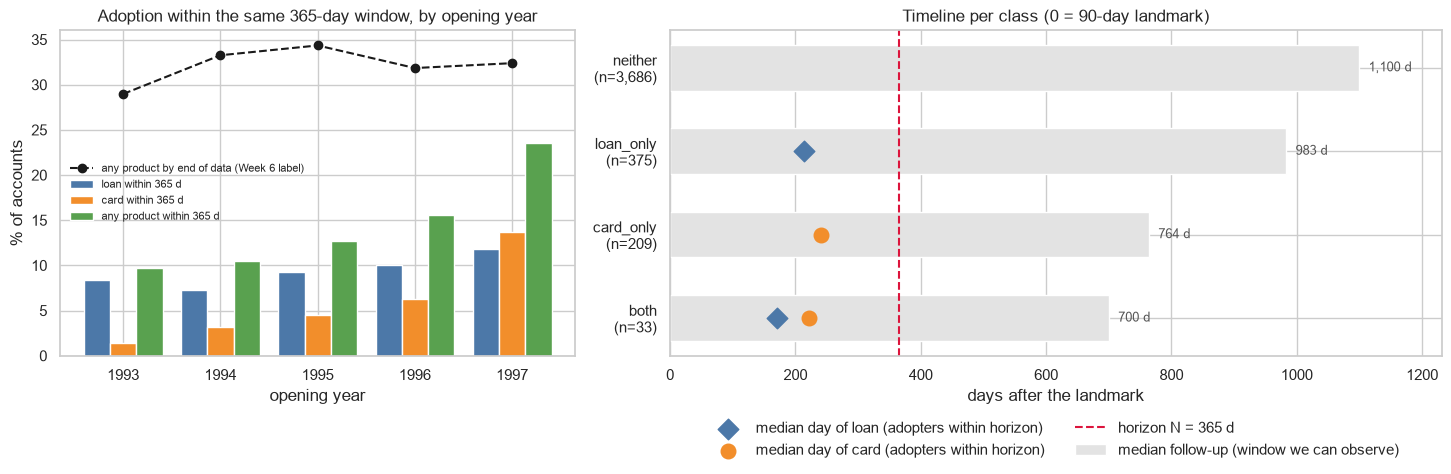

,n,loan %,card %,any %,any by end of data %
open_year,,,,,
1993,1139,8.300,1.400,9.700,29.000
1994,439,7.300,3.200,10.500,33.300
1995,661,9.200,4.500,12.700,34.300
1996,1363,10.100,6.300,15.600,31.800
1997,701,11.800,13.700,23.500,32.400


In [5]:
# left: adoption within the SAME horizon by opening year (the cohort effect); right: timeline per class
H = HORIZON_DAYS
by_year = model_df.groupby("open_year").agg(n=("y", "size"), loan=("loan_H", "mean"), card=("card_H", "mean"),
                                           any_H=("y", lambda s: (s > 0).mean()), any_end=("y_end", lambda s: (s > 0).mean()))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.5]})
x, w_ = np.arange(len(by_year)), 0.27
ax1.bar(x - w_, 100 * by_year["loan"], w_, color="#4C78A8", label=f"loan within {H} d")
ax1.bar(x, 100 * by_year["card"], w_, color="#F28E2B", label=f"card within {H} d")
ax1.bar(x + w_, 100 * by_year["any_H"], w_, color="#59A14F", label=f"any product within {H} d")
ax1.plot(x, 100 * by_year["any_end"], "k--o", label="any product by end of data (Week 6 label)")
ax1.set_xticks(x); ax1.set_xticklabels(by_year.index)
ax1.set(title=f"Adoption within the same {H}-day window, by opening year", xlabel="opening year", ylabel="% of accounts"); ax1.legend(fontsize=8, frameon=False)

tm = model_df.assign(days_to_loan=model_df["t_loan"].where(model_df["loan_H"] == 1), days_to_card=model_df["t_card"].where(model_df["card_H"] == 1))
g = tm.groupby("status4", observed=True).agg(n=("y", "size"), follow=("follow_up", "median"), loan=("days_to_loan", "median"),
                                             card=("days_to_card", "median")).reindex(CLASS_NAMES)
ypos = np.arange(len(g))[::-1]
ax2.barh(ypos, g["follow"], height=0.55, color="#E3E3E3", label="median follow-up (window we can observe)")
ax2.scatter(g["loan"], ypos, marker="D", s=110, color="#4C78A8", zorder=3, label="median day of loan (adopters within horizon)")
ax2.scatter(g["card"], ypos, marker="o", s=110, color="#F28E2B", zorder=3, label="median day of card (adopters within horizon)")
ax2.axvline(H, color="crimson", ls="--", lw=1.5, label=f"horizon N = {H} d")
for y_, f_ in zip(ypos, g["follow"]):
    ax2.text(f_ + 15, y_, f"{f_:,.0f} d", va="center", fontsize=9, color="#555")
ax2.set_yticks(ypos); ax2.set_yticklabels([f"{c}\n(n={n:,})" for c, n in zip(g.index, g["n"])])
ax2.set(title="Timeline per class (0 = 90-day landmark)", xlabel="days after the landmark", xlim=(0, g["follow"].max() * 1.12))
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
display(by_year.assign(**{"loan %": 100 * by_year["loan"], "card %": 100 * by_year["card"], "any %": 100 * by_year["any_H"], "any by end of data %": 100 * by_year["any_end"]})
        [["n", "loan %", "card %", "any %", "any by end of data %"]].round(1))

**How to read the figures.** *Left:* over the **same** 365-day window, adoption rises steeply with the opening year (any product: 9.7% for 1993 accounts to 23.5% for 1997 accounts; cards alone: 1.4% to 13.7%), whereas the dashed end-of-data rate stays flat at about 29-34% because older accounts simply had more time. An end-of-data label would therefore mix window length with cohort speed. *Right:* the grey bar is the window we can observe for a typical account of each class, the red line is the 365-day horizon, and the markers show when adopters adopted inside the horizon (typically between day 170 and day 240). `neither` accounts have no marker. The class sizes in the cohort are 3,686 `neither`, 375 `loan_only`, 209 `card_only` and only 33 `both`.

#### Random stratified split and preprocessing (fitted on the training set only)

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_classif

signed_log = FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)), feature_names_out="one-to-one")

def preprocess(train_ids, other_ids):
    # Fit imputation, signed-log choice, scaling, one-hot and correlation pruning on train_ids ONLY; transform the rest.
    tr = model_df.loc[train_ids]
    skew = tr[num_cols].skew()
    log_cols = skew[skew.abs() > 1].index.tolist(); lin_cols = [c for c in num_cols if c not in log_cols]
    ohe = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    tree_pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_cols), ("bin", "passthrough", bin_cols),
                                  ("cat", ohe(), cat_cols)], verbose_feature_names_out=False).set_output(transform="pandas")
    scaled_pre = ColumnTransformer([
        ("log", Pipeline([("imp", SimpleImputer(strategy="median")), ("log", signed_log), ("sc", StandardScaler())]), log_cols),
        ("lin", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), lin_cols),
        ("bin", "passthrough", bin_cols), ("cat", ohe(), cat_cols)], verbose_feature_names_out=False).set_output(transform="pandas")
    tree_pre.fit(tr[feature_cols]); scaled_pre.fit(tr[feature_cols])
    Xt_tr, Xs_tr = tree_pre.transform(tr[feature_cols]), scaled_pre.transform(tr[feature_cols])
    # redundancy pruning: for every pair with |Spearman| > 0.90 drop the predictor with lower mutual information
    corr = Xs_tr[num_cols].corr(method="spearman").abs()
    mi = pd.Series(mutual_info_classif(Xt_tr[num_cols], tr["y"], random_state=RANDOM_STATE), index=num_cols)
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
    drop = []
    for (a, b_), rho in pairs[pairs > 0.90].sort_values(ascending=False).items():
        if a in drop or b_ in drop: continue
        drop.append(a if mi[a] < mi[b_] else b_)
    keep_t, keep_s = [c for c in Xt_tr.columns if c not in drop], [c for c in Xs_tr.columns if c not in drop]
    out = {"train": {"tree": Xt_tr[keep_t], "scaled": Xs_tr[keep_s]}}
    for name, ids in other_ids.items():
        part = model_df.loc[ids, feature_cols]
        out[name] = {"tree": tree_pre.transform(part)[keep_t], "scaled": scaled_pre.transform(part)[keep_s]}
    return out, {"log_transformed": log_cols, "dropped_redundant": sorted(drop)}

# ---- primary split: time-based (train = accounts opened before 1997, test = 1997 accounts with a full horizon)
train_ids = model_df.index[model_df["open_date"] < TEMPORAL_SPLIT_DATE]
test_ids = model_df.index[model_df["open_date"] >= TEMPORAL_SPLIT_DATE]
# ---- secondary split: random, stratified on the four-class label (same accounts), used for the robustness comparison
rand_train_ids, rand_test_ids = train_test_split(model_df.index, test_size=0.20, stratify=model_df["y"], random_state=RANDOM_STATE)
rand_train_ids, rand_test_ids = pd.Index(sorted(rand_train_ids)), pd.Index(sorted(rand_test_ids))
P, prep_info = preprocess(train_ids, {"test": test_ids})
X_train_tree, X_test_tree = P["train"]["tree"], P["test"]["tree"]
X_train_scaled, X_test_scaled = P["train"]["scaled"], P["test"]["scaled"]
lab_cols = ["y", "status4", "y_end", "t_loan", "e_loan", "t_card", "e_card", "follow_up", "open_date", "open_year"]
lab_train, lab_test = model_df.loc[train_ids, lab_cols], model_df.loc[test_ids, lab_cols]
y_train, y_test = lab_train["y"].values, lab_test["y"].values

# two expanding-window folds inside the training set (train on earlier years, validate on the next year; used for tuning in the next stage)
yr = model_df.loc[train_ids, "open_year"].values
cv_folds = [(list(map(int, train_ids[yr <= v - 1])), list(map(int, train_ids[yr == v]))) for v in (1995, 1996)]

mix = pd.DataFrame({"accounts": [len(train_ids), len(test_ids)], "share": [len(train_ids) / len(model_df), len(test_ids) / len(model_df)]}, index=["train", "test"])
for k, c in enumerate(CLASS_NAMES):
    mix[c + " %"] = [100 * (y_train == k).mean(), 100 * (y_test == k).mean()]
mix["both (n)"] = [(y_train == 3).sum(), (y_test == 3).sum()]
display(mix.round(1))
print("Opening years in each split:")
display(pd.DataFrame({"train": model_df.loc[train_ids, "open_year"].value_counts(), "test": model_df.loc[test_ids, "open_year"].value_counts()}).fillna(0).astype(int).sort_index().T)
print(f"Majority-class accuracy on test: {100 * (y_test == 0).mean():.1f}%")
print(f"Matrices: {X_train_tree.shape} train / {X_test_tree.shape} test | NaNs: {int(X_train_tree.isna().sum().sum() + X_test_scaled.isna().sum().sum())}"
      f" | log-transformed: {len(prep_info['log_transformed'])} | dropped as redundant: {len(prep_info['dropped_redundant'])}")
print("Dropped:", prep_info["dropped_redundant"])

# ---- save everything for the next stage
X_train_tree.to_csv(OUT_DIR / "X_train_tree.csv"); X_test_tree.to_csv(OUT_DIR / "X_test_tree.csv")
X_train_scaled.to_csv(OUT_DIR / "X_train_scaled.csv"); X_test_scaled.to_csv(OUT_DIR / "X_test_scaled.csv")
lab_train.to_csv(OUT_DIR / "labels_train.csv"); lab_test.to_csv(OUT_DIR / "labels_test.csv")
json.dump({"split": "time-based: opened before 1997 (train) / 1997 (test)", "random_state": RANDOM_STATE, "class_names": CLASS_NAMES, "landmark_days": LANDMARK_DAYS, "horizon_days": HORIZON_DAYS,
           "cv_folds_expanding_window": cv_folds, "random_split": {"train": list(map(int, rand_train_ids)), "test": list(map(int, rand_test_ids))}, **prep_info}, open(OUT_DIR / "preprocessing_info.json", "w"))
pickle.dump({"train": {int(i): sequences[int(i)] for i in train_ids}, "test": {int(i): sequences[int(i)] for i in test_ids},
             "columns": SEQ_COLS, "vocab": VOCAB, "landmark_days": LANDMARK_DAYS}, open(OUT_DIR / "sequences.pkl", "wb"))

,accounts,share,neither %,loan_only %,card_only %,both %,both (n)
train,3602,0.800,87.500,8.500,3.500,0.500,19
test,701,0.200,76.500,9.800,11.700,2.000,14


Opening years in each split:


open_year,1993,1994,1995,1996,1997
train,1139,439,661,1363,0
test,0,0,0,0,701


Majority-class accuracy on test: 76.5%
Matrices: (3602, 41) train / (701, 41) test | NaNs: 0 | log-transformed: 21 | dropped as redundant: 14
Dropped: ['active_days', 'amt_mean', 'amt_std', 'bal_max', 'bal_mean', 'bal_min', 'bal_std', 'credit_sum', 'debit_sum', 'n_debit', 'n_txn', 'net_flow', 'spend_to_income', 'unemp96']


### Task 1: Model Selection and Training

After ensuring your data is preprocessed and ready, the next step is to dive into the core of machine learning: training models on your dataset.

**Objective**: Select and train appropriate machine learning models for your project using your preprocessed dataset.




**Instructions:**

**1. Model Selection Criteria**: When choosing a model, consider the following points as guidance:

   - **Nature of Your Problem**: Determine whether your project involves classification, regression, clustering, or another type of machine learning problem. 
   
   
   - **Size and Type of Your Data**: Assess the volume (size) of your dataset and the nature of your data (numerical, categorical, or a mix). For exmaple, for large datasets, Gradient Boosting can be effective but may require significant computational resources. For mixed data types, models like Random Forest, Gradient Boosting, and Decision Trees can efficiently handle both numerical and categorical data without extensive preprocessing.

   - **Features of the Dataset**: Consider the number of features in your dataset. Some models perform well on high-dimensional data, such as Support Vector Machines, Random Forests, and certain types of Neural Networks. Others, like K-Nearest Neighbors may be more effective in lower-dimensional spaces. For datasets with a very large number of features, models with built-in feature selection or regularization (like Lasso or Ridge Regression) can be beneficial. Principal Component Analysis (PCA) or other dimensionality reduction techniques might be necessary as a preprocessing step for some models when dealing with high-dimensional data.
   

   - **Interpretability of the Model**: Consider the importance of being able to interpret and explain your model's decisions. Decision Trees, Logistic Regression, and Linear Regression are highly interpretable, making them suitable for applications where decisions need to be explained, such as in healthcare or finance for credit scoring. Random Forests offer a balance between performance and interpretability through feature importance measures. In contrast, complex ensemble methods or deep learning models are often considered "black box" models and may not be suitable when high interpretability is required.
   
   
   - **Computational Efficiency**: Consider the computational resources you have available and the efficiency of the model in both training and prediction. Logistic Regression, Naive Bayes, and Linear Regression are computationally efficient, making them great choices for projects with limited resources or requiring quick responses. However, models like Random Forest, Gradient Boosting, and Neural Networks tend to require more computational power, especially with large datasets.
     

   - **Scalability of the Model**: If you expect the size of your dataset to increase significantly in the future, consider models that can handle large-scale data efficiently. Models such as Random Forest, Gradient Boosting, XGBoost, LightGBM, and Neural Networks are well-suited for large datasets. In contrast, models like K-Nearest Neighbors or Naive Bayes might struggle with scalability as dataset size grows.

     
   - **Robustness of the Model**: Evaluate the model’s sensitivity to outliers and noisy data. Models like Random Forest, Gradient Boosting, and ensemble methods are generally more robust and can handle noisy data effectively. In contrast, models such as single Decision Trees and K-Nearest Neighbors are more sensitive to outliers and can be affected by noisy data.


   - **Balance of the Data**: Assess whether your dataset has an imbalance in class distribution. Some models, like Random Forest, Support Vector Machines (SVM), XGBoost, LightGBM, and Gradient Boosting, are well-suited to handle imbalanced data either by adjusting parameters or using weighted classes. However, models such as Logistic Regression and Naive Bayes may require additional techniques like oversampling, undersampling, or weighting to manage class imbalance effectively.

   - **Hyperparameters of the Model**: Consider the number of hyperparameters and the difficulty of tuning them. Models like Support Vector Machines (SVM), Neural Networks, Gradient Boosting, XGBoost, and LightGBM often have many hyperparameters and may require extensive tuning to achieve optimal performance. On the other hand, models like Naive Bayes, K-Nearest Neighbors, and Linear Regression are simpler with fewer hyperparameters, making them easier to tune.

Note: *These factors may seem a bit complex, and some models mentioned (like Neural Networks) have not been covered in our course yet. But don't worry, this list is mainly meant to give you an overview and serve as a reference. In your project, you can focus on a few key aspects that align with your understanding and project needs. The purpose of this guide is to help you start thinking about the model selection process and gradually understand the characteristics and suitability of different models. As you continue learning about machine learning and gain more practice, the importance and application of these factors will become clearer. Additionally, in real-world applications, model selection might vary depending on the specific situation, and you may encounter considerations that are not covered in this list.*



**2. Exploration of Models**: Based on your criteria, choose **at least three different machine learning algorithms** to test. Common choices include:

**For Classification**:

- Logistic Regression: Simple and interpretable, good for linearly separable data.
- Support Vector Machines (SVM): Effective for high-dimensional spaces, works well with clear margin of separation.
- Decision Trees: Highly interpretable, handles non-linear relationships well.
- Random Forest: Robust to overfitting, handles large datasets and high dimensionality.
- Gradient Boosting (e.g., XGBoost, LightGBM): Often provides top performance, good with mixed data types.
- K-Nearest Neighbors (KNN): Simple and effective for small to medium datasets, sensitive to local structure.
- Naive Bayes: Fast and efficient, particularly good for text classification and high-dimensional, discrete data.


**For Regression**:

- Linear Regression: Simple, interpretable, fast for large datasets.
- Ridge Regression: Good when multicollinearity is present, uses L2 regularization.
- Lasso Regression: Performs feature selection, uses L1 regularization.
- Elastic Net: Combines Ridge and Lasso, balancing between the two.
- Decision Trees: Can capture non-linear relationships, prone to overfitting.
- Random Forest: Robust, handles non-linearity and interactions well.
- Gradient Boosting: Often provides top performance, can overfit if not tuned properly.
- Support Vector Regression (SVR): Good for high-dimensional spaces, can use kernel trick for non-linear relationships. May be slower for large datasets.

**For Clustering**:

- K-Means: Ideal for identifying clear, spherical clusters based on distance. Fast and simple.
- Hierarchical Clustering: Best for producing a tree of clusters, which is useful for hierarchical data. Provides a dendrogram visualization.
- DBSCAN (Density-Based Spatial Clustering of Applications with Noise): Effective for data with clusters of varying shapes and sizes, and for identifying outliers. Doesn't require specifying number of clusters.

**3. Training the Models**:

- **Train Each Selected Model**: Train each of the selected models using your preprocessed training data (e.g., X_train_scaled or equivalent). 


- **Baseline Performance**: Before diving deep into hyperparameter tuning, establish a baseline performance using a simple version of one of your selected models. This baseline model could be the initial version of your chosen algorithm with default parameters (e.g., a Random Forest with default settings or Logistic Regression without regularization). The purpose of this baseline is to provide a reference point to measure improvements from more complex models or tuning efforts.


**<span style="color:GREEN">4. Documentation:</span>**

<span style="color:GREEN">Provide a brief description of each model you have chosen, including its main characteristics and operational mechanisms. *You could explain why you believe each selected model is well-suited for your specific dataset and research questions. Consider factors such as the compatibility of the model with your data type, its common areas of application, and any unique strengths that make it particularly effective in addressing the challenges posed by your project.*</span>

#### Models selected and why

The task is a **four-class classification** of product adoption within a fixed 365-day horizon (`neither`, `loan_only`, `card_only`, `both`) with strong imbalance (about 86/9/5/1% overall, but only 77% `neither` in the 1997 test cohort) on 4,303 accounts and about 40 mixed numeric/binary/one-hot predictors, plus a **time-to-adoption** target with right-censoring and a raw **event stream** per account. That motivates one model family per question, from the simplest reference up to a continuous-time neural model. Random seed 42 everywhere; all models are trained on the training split only.

| Model | How it works | Why it suits this project |
|---|---|---|
| **Prior baseline** (`DummyClassifier`) | Always predicts the most frequent class; probabilities are the training class frequencies. | Defines the floor under imbalance: about 77% accuracy on the 1997 test cohort and an AUC of 0.5 with no skill. Every other model must beat it on macro-F1 and AUC, not accuracy. |
| **ElasticNet multinomial logistic regression** (`saga`) | Linear softmax model with a mix of L1 (feature selection) and L2 (shrinkage) penalties, on the scaled matrix. | Interpretable, fast, robust to the many correlated cash-flow predictors, and the reference for how much a linear model already explains. |
| **LightGBM** (flat 90-day features) | Gradient-boosted decision trees grown leaf-wise on the unscaled matrix. | Handles skew, interactions and mixed types without scaling, and tree ensembles are strong on medium-sized tabular data. Used as the strong hand-engineered-feature benchmark. |
| **Cause-specific Cox** (one per product) | Proportional-hazards regression of time to loan and time to card from the landmark, each product with its own censoring (end of 1998). | Uses *when* adoption happens and handles censoring explicitly, which a classifier ignores. Loans and cards are not competing events (a customer can take both), so each product keeps its own clock. |
| **Random Survival Forest** (one per product) | Forest of survival trees that split on log-rank statistics and average cumulative hazards. | Tests whether non-linear effects and interactions improve time-to-adoption ranking over the linear Cox model, with no proportional-hazards assumption. |
| **RMTPP-style GRU** | A GRU reads the 90-day transaction stream (log gap since the previous event, log amount, time in window, embedded type/operation/purpose marks) and is combined with the static predictors. Two heads: a 4-class softmax and RMTPP exponential intensities `log λ(t) = a(h) + w·t` for loan and card, trained with the censored point-process likelihood. | Tests the central hypothesis: does modelling the *continuous arrival of events* beat hand-aggregated 90-day features? The Du et al. (2016) RMTPP predicts the next event inside a stream. Here the same intensity-plus-marks idea is adapted to predict adoption *after* the landmark, so it is called "RMTPP-style". |

**From survival output to four classes.** For each account the survival models give the probability of adopting a loan, `p_loan`, and a card, `p_card`, within 365 days of the landmark (the same window that defines the label). Treating the two adoptions as independent, the class probabilities are `neither = (1-p_loan)(1-p_card)`, `loan_only = p_loan(1-p_card)`, `card_only = (1-p_loan)p_card` and `both = p_loan·p_card`. This independence assumption is an approximation and probably understates `both`. The C-index (ranking of adopters by predicted risk) is reported separately for each product.

**Initial versions.** All models are trained here with near-default settings and no class weighting; tuning, class weights for `both` and the temporal check come in the next stage.

#### Shared evaluation helpers

In [7]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from sksurv.metrics import concordance_index_censored

SHORT = ["neither", "loan", "card", "both"]
PROBA, CINDEX, METRICS = {}, {}, {}       # test-set probabilities, survival C-indices, metric rows (filled as models are trained)

def metrics_row(y_true, proba):
    # argmax decision; macro-F1, one-vs-rest AUC and per-class recall as required for the imbalanced 4-class target
    pred = proba.argmax(1)
    rec = recall_score(y_true, pred, average=None, labels=[0, 1, 2, 3], zero_division=0)
    row = {"accuracy": accuracy_score(y_true, pred),
           "macro_precision": precision_score(y_true, pred, average="macro", zero_division=0),
           "macro_recall": recall_score(y_true, pred, average="macro", zero_division=0),
           "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
           "ovr_auc_macro": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=[0, 1, 2, 3])}
    row.update({f"recall_{c}": r for c, r in zip(CLASS_NAMES, rec)})
    row.update({f"auc_{c}": roc_auc_score((y_true == k).astype(int), proba[:, k]) for k, c in enumerate(CLASS_NAMES)})
    return row

def evaluate(name, y_true, proba):
    # metrics_row + store the result for the comparison tables
    row = metrics_row(y_true, proba); METRICS[name] = row; PROBA[name] = proba
    return row

def four_class(p_loan, p_card):
    # independent product adoptions -> [neither, loan_only, card_only, both]; rows sum to 1
    return np.column_stack([(1 - p_loan) * (1 - p_card), p_loan * (1 - p_card), (1 - p_loan) * p_card, p_loan * p_card])

def cindex(lab, prod, risk):
    return concordance_index_censored(lab[f"e_{prod}"].astype(bool).values, lab[f"t_{prod}"].astype(float).values, np.asarray(risk))[0]

#### Baselines: prior, ElasticNet logistic regression, LightGBM

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

t0 = time.time()
# 1) prior baseline: always predicts the most frequent class, probabilities = training class frequencies
dummy = DummyClassifier(strategy="prior").fit(X_train_tree, y_train)
evaluate("Prior baseline", y_test, dummy.predict_proba(X_test_tree))

# 2) multinomial logistic regression with ElasticNet penalty (needs scaled inputs)
enet = LogisticRegression(C=1.0, l1_ratio=0.5, solver="saga", max_iter=5000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
evaluate("ElasticNet LR", y_test, enet.predict_proba(X_test_scaled))

# 3) LightGBM on the original-unit (tree) matrix, near-default settings: the untuned reference point
lgbm = LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
lgbm.fit(X_train_tree, y_train)
evaluate("LightGBM", y_test, lgbm.predict_proba(X_test_tree))
print(f"trained 3 baselines in {time.time() - t0:.1f}s | ElasticNet non-zero coefficients: {int((np.abs(enet.coef_) > 1e-8).sum())} of {enet.coef_.size}")
display(pd.DataFrame(METRICS).T[["accuracy", "macro_f1", "ovr_auc_macro"]].round(3))

trained 3 baselines in 16.2s | ElasticNet non-zero coefficients: 106 of 164


,accuracy,macro_f1,ovr_auc_macro
Prior baseline,0.765,0.217,0.500
ElasticNet LR,0.763,0.216,0.780
LightGBM,0.763,0.254,0.763


#### Time-aware models: cause-specific Cox and Random Survival Forest

In [9]:
from lifelines import CoxPHFitter
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

horizon_te = np.full(len(lab_test), float(HORIZON_DAYS))     # every account is scored at the same horizon
t0 = time.time()

def cox_cif(cph, X, t_eval):
    # P(adopt by t_eval) = 1 - exp(-H0(t_eval) * exp(x'b)), using lifelines' baseline cumulative hazard
    bch = cph.baseline_cumulative_hazard_.iloc[:, 0]
    idx = np.searchsorted(bch.index.values, t_eval, side="right") - 1
    H0 = np.where(idx >= 0, bch.values[np.clip(idx, 0, None)], 0.0)
    return 1 - np.exp(-H0 * cph.predict_partial_hazard(X).values)

def rsf_cif(rsf, X, t_eval):
    S = rsf.predict_survival_function(X, return_array=True)
    idx = np.searchsorted(rsf.unique_times_, t_eval, side="right") - 1
    return 1 - np.where(idx >= 0, S[np.arange(len(X)), np.clip(idx, 0, None)], 1.0)

cox, rsf, p_cox, p_rsf = {}, {}, {}, {}
for prod in ["loan", "card"]:
    # cause-specific Cox (ridge-penalised for the collinear one-hot and economic columns), scaled matrix
    d = X_train_scaled.copy(); d["T"], d["E"] = lab_train[f"t_{prod}"].values.astype(float), lab_train[f"e_{prod}"].values
    cox[prod] = CoxPHFitter(penalizer=0.1, l1_ratio=0.0).fit(d, "T", "E")
    p_cox[prod] = cox[prod].predict_partial_hazard(X_test_scaled).values
    # cause-specific Random Survival Forest, tree matrix
    ysurv = Surv.from_arrays(event=lab_train[f"e_{prod}"].astype(bool).values, time=lab_train[f"t_{prod}"].astype(float).values)
    rsf[prod] = RandomSurvivalForest(n_estimators=200, min_samples_leaf=15, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_tree, ysurv)
    p_rsf[prod] = rsf[prod].predict(X_test_tree)

CINDEX["Cox (cause-specific)"] = {p: cindex(lab_test, p, p_cox[p]) for p in ["loan", "card"]}
CINDEX["RSF (cause-specific)"] = {p: cindex(lab_test, p, p_rsf[p]) for p in ["loan", "card"]}

# four-class probabilities: P(loan within the horizon) and P(card within the horizon), combined as independent events
cif_cox = {p: cox_cif(cox[p], X_test_scaled, horizon_te) for p in ["loan", "card"]}
cif_rsf = {p: rsf_cif(rsf[p], X_test_tree, horizon_te) for p in ["loan", "card"]}
evaluate("Cox (cause-specific)", y_test, four_class(cif_cox["loan"], cif_cox["card"]))
evaluate("RSF (cause-specific)", y_test, four_class(cif_rsf["loan"], cif_rsf["card"]))
print(f"survival models fitted in {time.time() - t0:.1f}s")
display(pd.DataFrame(CINDEX).T.rename(columns={"loan": "C-index loan", "card": "C-index card"}).round(3))
display(pd.DataFrame({"Cox hazard ratio (loan)": np.exp(cox["loan"].params_), "Cox hazard ratio (card)": np.exp(cox["card"].params_)})
        .assign(m=lambda d: (np.log(d.iloc[:, 0]).abs() + np.log(d.iloc[:, 1]).abs())).sort_values("m", ascending=False).drop(columns="m").head(8).round(2))

del rsf; gc.collect()   # the forests are large (a survival curve is stored per leaf): free them once the predictions exist

survival models fitted in 20.8s


,C-index loan,C-index card
Cox (cause-specific),0.747,0.746
RSF (cause-specific),0.791,0.766


,Cox hazard ratio (loan),Cox hazard ratio (card)
covariate,,
has_insurance,1.730,0.820
has_pension,0.650,0.800
amt_max,1.280,1.250
frequency_weekly,1.320,0.890
frequency_monthly,0.760,1.110
bal_last,1.150,1.240
has_fees,0.860,0.850
frequency_per_transaction,1.250,0.920


75

#### RMTPP-style GRU on the 90-day event sequences

**Why the GRU trains in a separate process.** On macOS, PyTorch bundles its own OpenMP runtime (`libiomp5`), which can crash or hang when it shares a Python process with LightGBM or scikit-learn (each loads `libomp`). To keep the notebook robust on every machine, the GRU code below is written to `rmtpp_worker.py` and run as a **subprocess**. The notebook prepares the NumPy inputs, the worker trains the network and returns the predictions, and the evaluation continues as before. Training progress is streamed to the cell output.

In [10]:
%%writefile rmtpp_worker.py
# RMTPP-style GRU trainer, run as its own Python process (see the note above).
import os, sys, time, pickle
os.environ.setdefault("OMP_NUM_THREADS", "1"); os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(1)

class RMTPPStyle(nn.Module):
    # GRU over the 90-day event stream (gap, amount, time + embedded marks) -> shared body -> 4-class head and
    # RMTPP-style exponential intensities log lambda_p(t) = a_p(h) + w_p * t for loan and card, t = years since landmark.
    def __init__(self, n_static, hid=32, emb=4, body=64, drop=0.2):
        super().__init__()
        self.e_type, self.e_op, self.e_ks = nn.Embedding(3, emb), nn.Embedding(6, emb), nn.Embedding(8, emb)
        self.gru = nn.GRU(3 + 3 * emb, hid, batch_first=True)
        self.body = nn.Sequential(nn.Linear(hid + n_static, body), nn.ReLU(), nn.Dropout(drop))
        self.cls, self.a, self.w = nn.Linear(body, 4), nn.Linear(body, 2), nn.Parameter(torch.zeros(2))
    def forward(self, cont, cat, lens, static):
        x = torch.cat([cont, self.e_type(cat[..., 0]), self.e_op(cat[..., 1]), self.e_ks(cat[..., 2])], -1)
        _, h = self.gru(nn.utils.rnn.pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False))
        z = self.body(torch.cat([h[-1], static], 1))
        return self.cls(z), self.a(z).clamp(-10, 3), self.w.clamp(-2, 2)

def cum_haz(a, w, t):       # Lambda(t) = exp(a) * (exp(w t) - 1) / w  (closed form of the integrated intensity)
    small = w.abs() < 1e-4
    return torch.exp(a) * torch.where(small, t, torch.expm1(w * t) / torch.where(small, torch.ones_like(w), w))

def tens(d, idx=None):
    return {k: torch.as_tensor(v if idx is None else v[idx]) for k, v in d.items()}

def batch_losses(model, b, class_w=None):
    logits, a, w = model(b["cont"], b["cat"], b["lens"], b["static"])
    ll = (b["e"] * (a + w * b["t"]) - cum_haz(a, w, b["t"])).sum(1)     # event: log lambda(t) - Lambda(t); censored: -Lambda(t)
    return F.cross_entropy(logits, b["y"], weight=class_w), -ll.mean()

def four_class(p_loan, p_card):
    return np.column_stack([(1 - p_loan) * (1 - p_card), p_loan * (1 - p_card), (1 - p_loan) * p_card, p_loan * p_card])

def train_rmtpp(tr, va, class_w=None, seed=42, epochs=80, patience=10, lr=3e-3, wd=1e-4, lam=1.0, bs=128, verbose=True, **kw):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = RMTPPStyle(tr["static"].shape[1], **kw); opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    cw = None if class_w is None else torch.as_tensor(class_w, dtype=torch.float32)
    best, best_state, bad, vb, t0 = np.inf, None, 0, tens(va), time.time()
    for ep in range(epochs):
        model.train(); perm = rng.permutation(len(tr["y"]))
        for s in range(0, len(perm), bs):
            ce, nll = batch_losses(model, tens(tr, perm[s:s + bs]), cw); opt.zero_grad(); (ce + lam * nll).backward(); opt.step()
        model.eval()
        with torch.no_grad(): vce, vnll = batch_losses(model, vb, cw)
        val = float(vce + lam * vnll)
        if verbose and (ep % 5 == 0 or bad >= patience - 1):
            print(f"  epoch {ep + 1:3d} | val loss {val:.4f} | best {best:.4f} | no-improve {bad} | {time.time() - t0:.0f}s", flush=True)
        if val < best - 1e-4:
            best, bad, best_state = val, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval(); model.epochs_run = ep + 1
    return model

def predict_rmtpp(model, d):
    b = tens(d)
    with torch.no_grad():
        logits, a, w = model(b["cont"], b["cat"], b["lens"], b["static"])
        p_cls = F.softmax(logits, 1).numpy()
        cif = 1 - torch.exp(-cum_haz(a, w, b["horizon"][:, None].expand(-1, 2))).numpy()     # P(adopt within the horizon)
        risk = cum_haz(a, w, torch.ones_like(a)).numpy()                                      # 1-year cumulative hazard as ranking score
    return p_cls, four_class(cif[:, 0], cif[:, 1]), risk

if __name__ == "__main__":
    payload, out = pickle.load(open(sys.argv[1], "rb")), {}
    for run in payload["runs"]:
        kwargs = {k: v for k, v in run.items() if k != "name"}; t0 = time.time()
        print(f"training run '{run['name']}' ({torch.__version__}, {torch.get_num_threads()} thread(s))", flush=True)
        model = train_rmtpp(payload["train"], payload["val"], **kwargs)
        out[run["name"]] = {"predict": {k: predict_rmtpp(model, d) for k, d in payload["predict"].items()},
                            "epochs": model.epochs_run, "n_params": sum(p.numel() for p in model.parameters()),
                            "w": [round(float(x), 2) for x in model.w.detach().numpy()], "seconds": time.time() - t0}
    pickle.dump(out, open(sys.argv[2], "wb")); print("worker finished", flush=True)

Overwriting rmtpp_worker.py


In [11]:
import subprocess, sys
MAXLEN = max(len(s) for s in sequences.values())

def pack(ids, lab, Xs, static_cols):
    # NumPy arrays for the worker: padded event sequences, static predictors, labels and per-product survival targets
    n = len(ids); cont = np.zeros((n, MAXLEN, 3), np.float32); cat = np.zeros((n, MAXLEN, 3), np.int64); lens = np.zeros(n, np.int64)
    for k, i in enumerate(ids):
        s = sequences[int(i)]; m = len(s); lens[k] = m
        cont[k, :m, 0], cont[k, :m, 1], cont[k, :m, 2] = np.log1p(s[:, 1]), s[:, 2], s[:, 0] / LANDMARK_DAYS   # log gap, log amount, time in window
        cat[k, :m] = s[:, 3:6].astype(np.int64)                                                                  # type, operation, k-symbol ids
    L = lab.loc[ids]
    return {"cont": cont, "cat": cat, "lens": lens, "static": Xs.loc[ids, static_cols].values.astype(np.float32), "y": L["y"].values.astype(np.int64),
            "t": np.stack([L["t_loan"], L["t_card"]], 1).astype(np.float32) / 365.0, "e": np.stack([L["e_loan"], L["e_card"]], 1).astype(np.float32),
            "horizon": np.full(n, HORIZON_DAYS / 365.0, np.float32)}

def run_gru(tr_ids_all, te_ids, lab_tr, lab_te, Xs_tr, Xs_te, tag, verbose=True):
    # inner validation split for early stopping, inputs standardised with TRAIN statistics, training in the worker process
    static_cols = [c for c in Xs_tr.columns if c in STATIC_BASE or c.startswith(("frequency_", "region_"))]
    tr_ids, va_ids = train_test_split(tr_ids_all, test_size=0.15, stratify=lab_tr.loc[tr_ids_all, "y"], random_state=RANDOM_STATE)
    pk_tr, pk_va, pk_te = (pack(tr_ids, lab_tr, Xs_tr, static_cols), pack(va_ids, lab_tr, Xs_tr, static_cols), pack(te_ids, lab_te, Xs_te, static_cols))
    mask = np.arange(MAXLEN)[None, :] < pk_tr["lens"][:, None]
    mu, sd = pk_tr["cont"][mask].mean(0), pk_tr["cont"][mask].std(0) + 1e-6
    for d in (pk_tr, pk_va, pk_te):
        d["cont"] = ((d["cont"] - mu) / sd) * (np.arange(MAXLEN)[None, :, None] < d["lens"][:, None, None])
    payload_path, result_path = OUT_DIR / f"rmtpp_payload_{tag}.pkl", OUT_DIR / f"rmtpp_results_{tag}.pkl"
    pickle.dump({"train": pk_tr, "val": pk_va, "predict": {"test": pk_te}, "runs": [{"name": "initial", "seed": RANDOM_STATE}]}, open(payload_path, "wb"))
    proc = subprocess.Popen([sys.executable, "-u", "rmtpp_worker.py", str(payload_path), str(result_path)],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        if verbose: print(line, end="")                                              # live training log
    if proc.wait() != 0: raise RuntimeError(f"rmtpp_worker.py exited with code {proc.returncode}")
    return pickle.load(open(result_path, "rb"))["initial"], len(static_cols)

t0 = time.time()
res, n_static = run_gru(train_ids, test_ids, lab_train, lab_test, X_train_scaled, X_test_scaled, tag="primary")
p_cls, p_haz, risk = res["predict"]["test"]
evaluate("RMTPP-style (class head)", y_test, p_cls)
evaluate("RMTPP-style (intensity head)", y_test, p_haz)
CINDEX["RMTPP-style GRU"] = {p: cindex(lab_test, p, risk[:, k]) for k, p in enumerate(["loan", "card"])}
print(f"GRU: {res['n_params']:,} parameters, stopped after {res['epochs']} epochs, {res['seconds']:.0f}s in the worker, {time.time() - t0:.0f}s in total | "
      f"static inputs: {n_static} | learned time-drift w (loan, card) = {res['w']} per year")

training run 'initial' (2.2.2, 1 thread(s))
  epoch   1 | val loss 2.1156 | best inf | no-improve 0 | 1s
  epoch   6 | val loss 1.6576 | best 1.6639 | no-improve 0 | 2s
  epoch  11 | val loss 1.6263 | best 1.6369 | no-improve 1 | 4s
  epoch  16 | val loss 1.6189 | best 1.6204 | no-improve 2 | 6s
  epoch  21 | val loss 1.6137 | best 1.6161 | no-improve 3 | 7s
  epoch  26 | val loss 1.6254 | best 1.6137 | no-improve 4 | 9s
  epoch  31 | val loss 1.6285 | best 1.6137 | no-improve 9 | 11s
worker finished
GRU: 8,684 parameters, stopped after 31 epochs, 12s in the worker, 16s in total | static inputs: 22 | learned time-drift w (loan, card) = [-0.26, 0.04] per year


### Task 2: Model Initial Evaluation

**Objective**: Conduct an initial performance evaluation of the trained models using the test set. This assessment will offer insights into each model's effectiveness and identify potential areas for improvement.


**Instructions:**

- **Evaluate Using Test Set**: Assess the performance of each trained model on the test set. This helps to measure the model's ability to generalize to unseen data and avoid overfitting, providing a realistic indication of how the models might perform in real-world scenarios.


- **Selection of Evaluation Metrics:**

   - **For regression tasks**: 

      - Mean Squared Error (MSE): Measures the average squared difference between predicted and actual values.
      - Root Mean Squared Error (RMSE): The square root of MSE, in the same unit as the target variable.
      - R-squared: Indicates the proportion of variance in the dependent variable predictable from the independent variable(s).
    <br>
        

   
   - **For classification tasks**:
     
     - Accuracy: The proportion of correct predictions among the total number of cases examined.
     - Precision: The proportion of true positive predictions among all positive predictions.
     - Recall: The proportion of true positive predictions among all actual positive cases.
     - F1-score: The harmonic mean of precision and recall.
     - Area Under the ROC Curve (AUC-ROC): Measures the model's ability to distinguish between classes.
   
   
*Note: For implementing these metrics, you could refer to the 'Evaluation Metrics and Scoring' lectures provided in Week 6.*

Remember, this is an initial evaluation. The results will guide you in deciding which models to focus on for further improvement in the next stages of your project.



<span style="color:green;">**Document Performance and Initial Analysis**:</span>

<span style="color:green;">Prepare 1-2 paragraphs that:</span>
- <span style="color:green;">Summarize the performance metrics for each model based on their evaluation on the test set. For classification tasks, be sure to include key metrics such as accuracy, precision, recall, and F1-score. For regression tasks, include RMSE as a required metric, and you may also include other relevant metrics such as MSE and R-squared. After presenting the metrics, briefly discuss which metrics are most relevant to your problem and explain why. </span> For example:

    - For regression tasks: If your project focuses on predicting continuous variables (such as house prices or sales), MSE and RMSE clearly show the prediction error of the model and help you assess its performance in numerical prediction. If you're also interested in how well the model fits the overall data, R-squared would be an appropriate metric.

    - For classification tasks: If your dataset has balanced classes, accuracy is a simple and straightforward evaluation metric. However, if your data is imbalanced, precision, recall, and F1-score become more important, especially when you need to balance between false positives and false negatives. If you're looking to assess the overall classification performance of the model, particularly in imbalanced datasets, AUC-ROC is a good metric.


- <span style="color:green;">Provide your initial impressions on which models appear to be the best candidates for your project's objectives. Discuss any models that stand out in terms of performance or those that may require further adjustments or investigation.</span>

This concise documentation will serve as a foundational analysis, guiding your next steps in model optimization and fine-tuning, as well as in the final evaluation of the model, both scheduled for next week.


,accuracy,macro_precision,macro_recall,macro_f1,ovr_auc_macro,recall_neither,recall_loan_only,recall_card_only,recall_both
Prior baseline,0.765,0.191,0.250,0.217,0.500,1.000,0.000,0.000,0.000
ElasticNet LR,0.763,0.191,0.250,0.216,0.780,0.998,0.000,0.000,0.000
LightGBM,0.763,0.401,0.268,0.254,0.763,0.987,0.072,0.012,0.000
Cox (cause-specific),0.765,0.191,0.250,0.217,0.777,1.000,0.000,0.000,0.000
RSF (cause-specific),0.765,0.191,0.250,0.217,0.809,1.000,0.000,0.000,0.000
RMTPP-style (class head),0.765,0.191,0.250,0.217,0.762,1.000,0.000,0.000,0.000
RMTPP-style (intensity head),0.765,0.191,0.250,0.217,0.774,1.000,0.000,0.000,0.000


One-vs-rest AUC per class:


,auc_neither,auc_loan_only,auc_card_only,auc_both
Prior baseline,0.500,0.500,0.500,0.500
ElasticNet LR,0.773,0.794,0.717,0.837
LightGBM,0.743,0.734,0.735,0.839
Cox (cause-specific),0.759,0.744,0.734,0.870
RSF (cause-specific),0.785,0.799,0.763,0.889
RMTPP-style (class head),0.768,0.798,0.675,0.808
RMTPP-style (intensity head),0.767,0.794,0.700,0.834


Survival C-index on the test set (time-aware ranking of adopters):


,loan,card
Cox (cause-specific),0.747,0.746
RSF (cause-specific),0.791,0.766
RMTPP-style GRU,0.794,0.706


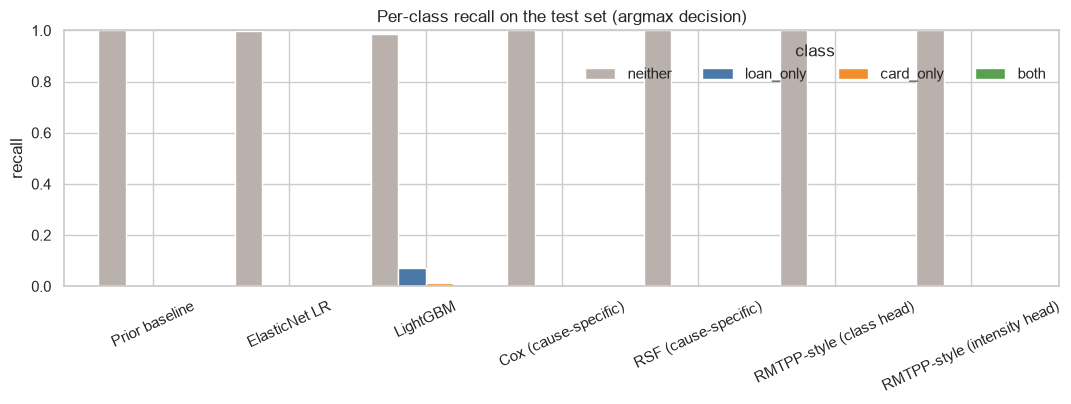

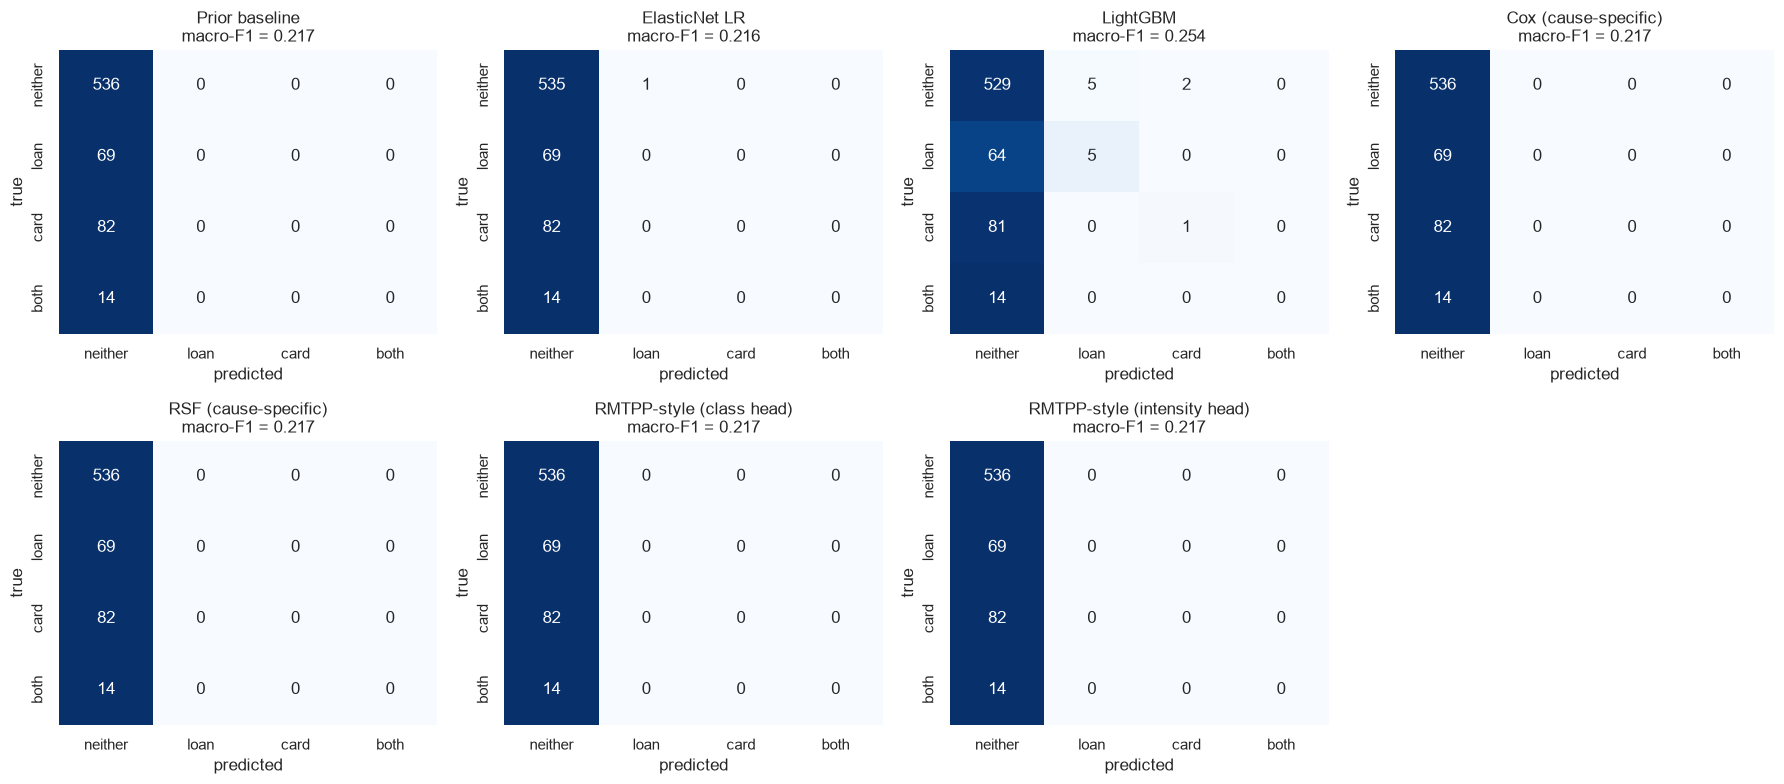

In [12]:
# ---- main results table (1 row per model, test set, argmax decision)
res = pd.DataFrame(METRICS).T
order = ["Prior baseline", "ElasticNet LR", "LightGBM", "Cox (cause-specific)", "RSF (cause-specific)", "RMTPP-style (class head)", "RMTPP-style (intensity head)"]
res = res.loc[order]
display(res[["accuracy", "macro_precision", "macro_recall", "macro_f1", "ovr_auc_macro"] + [f"recall_{c}" for c in CLASS_NAMES]].round(3))
print("One-vs-rest AUC per class:"); display(res[[f"auc_{c}" for c in CLASS_NAMES]].round(3))
print("Survival C-index on the test set (time-aware ranking of adopters):")
display(pd.DataFrame(CINDEX).T.rename(columns={"loan": "loan", "card": "card"}).round(3))

# ---- per-class recall
fig, ax = plt.subplots(figsize=(11, 4.2))
res[[f"recall_{c}" for c in CLASS_NAMES]].rename(columns=lambda c: c.replace("recall_", "")).plot(kind="bar", ax=ax, width=0.8, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
ax.set(title="Per-class recall on the test set (argmax decision)", ylabel="recall", ylim=(0, 1)); ax.tick_params(axis="x", rotation=25)
ax.legend(title="class", ncol=4, frameon=False); plt.tight_layout(); plt.show()

# ---- confusion matrices (colour = row-normalised, numbers = counts)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, name in zip(axes.ravel(), order):
    cm = confusion_matrix(y_test, PROBA[name].argmax(1), labels=[0, 1, 2, 3])
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, xticklabels=SHORT, yticklabels=SHORT)
    ax.set(title=f"{name}\nmacro-F1 = {METRICS[name]['macro_f1']:.3f}", xlabel="predicted", ylabel="true")
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

In [13]:
# per-class precision, recall and F1 (argmax decision) for every model
from sklearn.metrics import precision_recall_fscore_support
rows = {}
for name in order:
    p, r, f, _ = precision_recall_fscore_support(y_test, PROBA[name].argmax(1), labels=[0, 1, 2, 3], zero_division=0)
    rows[name] = {(c, m): v for c, pv, rv, fv in zip(CLASS_NAMES, p, r, f) for m, v in [("precision", pv), ("recall", rv), ("F1", fv)]}
per_class = pd.DataFrame(rows).T
per_class.columns = pd.MultiIndex.from_tuples(per_class.columns)
print("Per-class precision / recall / F1 on the test set:")
display(per_class.round(3))

Per-class precision / recall / F1 on the test set:


neither              loan_only              card_only                   both             
                             precision recall    F1 precision recall    F1 precision recall    F1 precision recall    F1
Prior baseline                   0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
ElasticNet LR                    0.764  0.998 0.866     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
LightGBM                         0.769  0.987 0.864     0.500  0.072 0.127     0.333  0.012 0.024     0.000  0.000 0.000
Cox (cause-specific)             0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
RSF (cause-specific)             0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
RMTPP-style (class head)         0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
RMTPP-style (intensity head)     0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000

#### Binary view: loan within 365 days and card within 365 days (more stable than the rare `both` class)

In [14]:
# binary view of the same predictions: P(loan within horizon) = P(loan_only) + P(both), P(card within horizon) = P(card_only) + P(both)
from sklearn.metrics import average_precision_score
yl, yc = np.isin(y_test, [1, 3]).astype(int), np.isin(y_test, [2, 3]).astype(int)
rows = {}
for name in order:
    p = PROBA[name]; pl, pc = p[:, 1] + p[:, 3], p[:, 2] + p[:, 3]
    rows[name] = {"loan AUC": roc_auc_score(yl, pl), "loan PR-AUC": average_precision_score(yl, pl),
                  "card AUC": roc_auc_score(yc, pc), "card PR-AUC": average_precision_score(yc, pc)}
print(f"Test accounts with a loan within {HORIZON_DAYS} days: {yl.sum()} ({100 * yl.mean():.1f}%), with a card: {yc.sum()} ({100 * yc.mean():.1f}%)"
      f" | PR-AUC of a random ranking equals these shares")
display(pd.DataFrame(rows).T.round(3))

Test accounts with a loan within 365 days: 83 (11.8%), with a card: 96 (13.7%) | PR-AUC of a random ranking equals these shares


,loan AUC,loan PR-AUC,card AUC,card PR-AUC
Prior baseline,0.500,0.118,0.500,0.137
ElasticNet LR,0.807,0.353,0.749,0.278
LightGBM,0.748,0.300,0.753,0.275
Cox (cause-specific),0.768,0.282,0.761,0.281
RSF (cause-specific),0.815,0.393,0.782,0.300
RMTPP-style (class head),0.812,0.346,0.696,0.236
RMTPP-style (intensity head),0.809,0.342,0.717,0.250


#### Sensitivity: end-of-data label (Week 6) vs fixed 365-day horizon

In [15]:
# sensitivity: the Week 6 label (adopted at any time before the end of the data) on the same accounts and the same split
y_end_tr, y_end_te = lab_train["y_end"].values, lab_test["y_end"].values
enet_e = LogisticRegression(C=1.0, l1_ratio=0.5, solver="saga", max_iter=5000, random_state=RANDOM_STATE).fit(X_train_scaled, y_end_tr)
lgbm_e = LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1).fit(X_train_tree, y_end_tr)
rows = {}
for name, proba in [("ElasticNet LR", enet_e.predict_proba(X_test_scaled)), ("LightGBM", lgbm_e.predict_proba(X_test_tree))]:
    rows[(name, "end-of-data label (Week 6)")] = evaluate(f"{name} [end-of-data label]", y_end_te, proba)
    rows[(name, f"{HORIZON_DAYS}-day horizon label (primary)")] = METRICS[name]
sens = pd.DataFrame(rows).T[["accuracy", "macro_f1", "ovr_auc_macro", "recall_neither", "recall_loan_only", "recall_card_only", "recall_both"]]
print("Class shares in the test set, end-of-data label:", dict(zip(CLASS_NAMES, np.round(np.bincount(y_end_te, minlength=4) / len(y_end_te), 3))))
display(sens.round(3))

Class shares in the test set, end-of-data label: {'neither': 0.676, 'loan_only': 0.121, 'card_only': 0.167, 'both': 0.036}


accuracy  macro_f1  ovr_auc_macro  recall_neither  recall_loan_only  recall_card_only  recall_both
ElasticNet LR end-of-data label (Week 6)          0.673     0.308          0.783           0.954             0.141             0.051        0.080
              365-day horizon label (primary)     0.763     0.216          0.780           0.998             0.000             0.000        0.000
LightGBM      end-of-data label (Week 6)          0.666     0.351          0.756           0.911             0.200             0.137        0.080
              365-day horizon label (primary)     0.763     0.254          0.763           0.987             0.072             0.012        0.000

#### Secondary comparison: random stratified split vs time-based split

Primary test set (time-based): 701 accounts, 23.5% adopt within 365 days, 14 with both | secondary test set (random): 861 accounts, 14.4% adopt, 7 with both  (47s)


time-based split (primary)                                 random stratified split (secondary)                                
                                               macro_f1 ovr_auc_macro loan_auc card_auc                            macro_f1 ovr_auc_macro loan_auc card_auc
Prior baseline                                    0.217         0.500    0.500    0.500                               0.231         0.500    0.500    0.500
ElasticNet LR                                     0.216         0.780    0.807    0.749                               0.243         0.777    0.805    0.719
LightGBM                                          0.254         0.763    0.748    0.753                               0.264         0.774    0.788    0.744
Cox (cause-specific)                              0.217         0.777    0.768    0.761                               0.244         0.786    0.786    0.765
RSF (cause-specific)                              0.217         0.809    0.815    0.782                               0.231         0.812    0.821    0.786
RMTPP-style (class head)                          0.217         0.762    0.812    0.696                               0.270         0.799    0.823    0.747
RMTPP-style (intensity head)                      0.217         0.774    0.809    0.717                               0.243         0.807    0.834    0.749

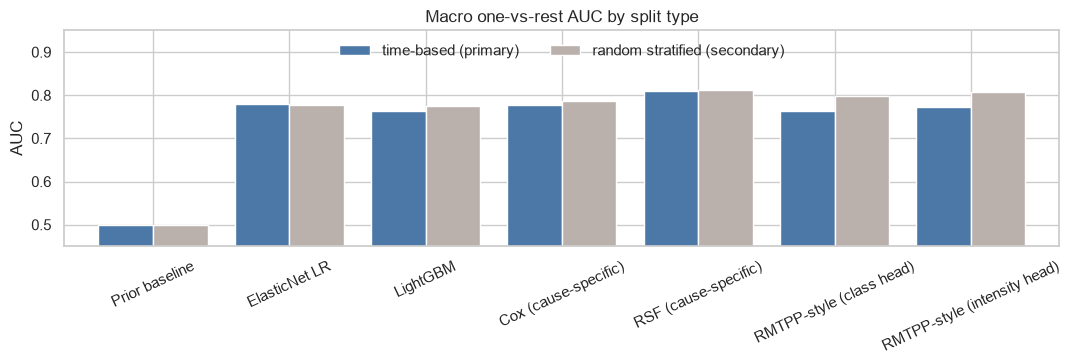

In [16]:
# secondary comparison: random stratified 80/20 split of the same accounts, same models and settings
def summary_row(y_true, proba):
    r = metrics_row(y_true, proba)
    yl, yc = np.isin(y_true, [1, 3]).astype(int), np.isin(y_true, [2, 3]).astype(int)
    return {"accuracy": r["accuracy"], "macro_f1": r["macro_f1"], "ovr_auc_macro": r["ovr_auc_macro"],
            "loan_auc": roc_auc_score(yl, proba[:, 1] + proba[:, 3]), "card_auc": roc_auc_score(yc, proba[:, 2] + proba[:, 3])}

def fit_all(tr_ids, te_ids, tag):
    P2, _ = preprocess(tr_ids, {"test": te_ids})            # preprocessing re-fitted on this split's training accounts only
    Xt_tr, Xt_te, Xs_tr, Xs_te = P2["train"]["tree"], P2["test"]["tree"], P2["train"]["scaled"], P2["test"]["scaled"]
    L_tr, L_te = model_df.loc[tr_ids, lab_cols], model_df.loc[te_ids, lab_cols]
    y_tr, y_te = L_tr["y"].values, L_te["y"].values
    horizon, out = np.full(len(te_ids), float(HORIZON_DAYS)), {}
    out["Prior baseline"] = DummyClassifier(strategy="prior").fit(Xt_tr, y_tr).predict_proba(Xt_te)
    out["ElasticNet LR"] = LogisticRegression(C=1.0, l1_ratio=0.5, solver="saga", max_iter=5000, random_state=RANDOM_STATE).fit(Xs_tr, y_tr).predict_proba(Xs_te)
    out["LightGBM"] = LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1).fit(Xt_tr, y_tr).predict_proba(Xt_te)
    cif_c, cif_r = {}, {}
    for prod in ["loan", "card"]:
        d = Xs_tr.copy(); d["T"], d["E"] = L_tr[f"t_{prod}"].values.astype(float), L_tr[f"e_{prod}"].values
        cif_c[prod] = cox_cif(CoxPHFitter(penalizer=0.1, l1_ratio=0.0).fit(d, "T", "E"), Xs_te, horizon)
        ysv = Surv.from_arrays(event=L_tr[f"e_{prod}"].astype(bool).values, time=L_tr[f"t_{prod}"].astype(float).values)
        forest = RandomSurvivalForest(n_estimators=200, min_samples_leaf=15, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_tr, ysv)
        cif_r[prod] = rsf_cif(forest, Xt_te, horizon)
    out["Cox (cause-specific)"], out["RSF (cause-specific)"] = four_class(cif_c["loan"], cif_c["card"]), four_class(cif_r["loan"], cif_r["card"])
    res_g, _ = run_gru(tr_ids, te_ids, L_tr, L_te, Xs_tr, Xs_te, tag=tag, verbose=False)
    out["RMTPP-style (class head)"], out["RMTPP-style (intensity head)"] = res_g["predict"]["test"][0], res_g["predict"]["test"][1]
    return {k: summary_row(y_te, v) for k, v in out.items()}, y_te

gc.collect()
t0 = time.time()
sec_rows, y_sec = fit_all(rand_train_ids, rand_test_ids, tag="random")
prim_rows = {k: summary_row(y_test, PROBA[k]) for k in order}
print(f"Primary test set (time-based): {len(y_test)} accounts, {100 * (y_test > 0).mean():.1f}% adopt within {HORIZON_DAYS} days, {int((y_test == 3).sum())} with both | "
      f"secondary test set (random): {len(y_sec)} accounts, {100 * (y_sec > 0).mean():.1f}% adopt, {int((y_sec == 3).sum())} with both  ({time.time() - t0:.0f}s)")
cmp_ = pd.concat({"time-based split (primary)": pd.DataFrame(prim_rows).T, "random stratified split (secondary)": pd.DataFrame(sec_rows).T}, axis=1)
display(cmp_.loc[:, [(s, m) for s in ["time-based split (primary)", "random stratified split (secondary)"] for m in ["macro_f1", "ovr_auc_macro", "loan_auc", "card_auc"]]].round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
pd.DataFrame({"time-based (primary)": [prim_rows[k]["ovr_auc_macro"] for k in order],
              "random stratified (secondary)": [sec_rows[k]["ovr_auc_macro"] for k in order]}, index=order).plot(kind="bar", ax=ax, width=0.8, color=["#4C78A8", "#BAB0AC"])
ax.set(title="Macro one-vs-rest AUC by split type", ylabel="AUC", ylim=(0.45, 0.95)); ax.tick_params(axis="x", rotation=25); ax.legend(frameon=False, ncol=2, loc="upper center")
plt.tight_layout(); plt.show()

#### Initial performance and first impressions

**Metrics.** The 701 test accounts (opened in 1997) are 76.5% `neither`, so accuracy is almost uninformative (prior baseline 0.765, best model 0.765), and with the default argmax rule most models simply predict `neither`: five of the six models have the same macro-F1 as the baseline (0.216 to 0.217). LightGBM is the only one that predicts other classes (macro-F1 0.254); it recovers 5 of 69 `loan_only` and 1 of 82 `card_only` accounts, and no model recovers any of the 14 `both` accounts. This is an imbalance and decision-rule problem more than a lack of signal. The rank-based metrics are clearly above chance: macro one-vs-rest AUC is 0.763 to 0.809 against 0.500 for the baseline, and RSF is the most consistent ranker (macro AUC 0.809; loan AUC 0.815 with PR-AUC 0.393 against a random-ranking level of 0.118; card AUC 0.782 with PR-AUC 0.300 against 0.137; C-index 0.791 for loans and 0.766 for cards). The GRU matches RSF on loans (C-index 0.793) but is weaker on cards (0.727), and the cause-specific Cox model is the weakest on loans (C-index 0.747). With 83 loan and 96 card positives and a single seed, differences of about 0.02 are within noise, so I read the results as "RSF slightly ahead, no clear winner among the rest".

**Initial impressions.** (1) The first 90 days carry a real but modest signal (AUC about 0.75 to 0.81) that transfers to a later cohort. (2) The test cohort differs from the training data: 23.5% of the 1997 accounts adopt a product within 365 days against 12.5% of the earlier accounts (and `both` is 2.0% against 0.5%), so models trained on earlier years under-predict adoption and a 0.5-style cut-off is far too high. This prior shift affects hard-label metrics much more than AUC, and it is why class weights and a recalibrated decision rule are the first optimization steps. (3) The random stratified split of the same accounts gives macro AUCs of 0.774 to 0.812 against 0.763 to 0.809 for the time-based split. The two are close for ElasticNet, Cox and RSF (differences of at most 0.01) and further apart for LightGBM (0.011) and the GRU (0.032 for the class head, 0.022 for the intensity head), so random splitting was mildly optimistic, most for the GRU. The two test sets contain different accounts and different base rates (14.4% against 23.5% adopters), so only the AUC comparison is meaningful. (4) The sensitivity analysis shows that the label definition changes the hard-label metrics but not the ranking skill: on the Week 6 end-of-data label ElasticNet and LightGBM reach macro-F1 of 0.308 and 0.351 with AUC 0.783 and 0.756, against 0.216 with 0.780 and 0.254 with 0.763 on the fixed-horizon label; the higher macro-F1 reflects the more balanced classes of the old label (68% instead of 76% `neither`). (5) The GRU, which sees only the raw event stream plus static attributes, is competitive on loans but does not beat the tabular and survival models. The next stage adds class weighting for `both`, tuning on the two expanding-window folds, a recalibrated decision rule, repeated seeds with confidence intervals, and a comparison of tuned and initial models on this 1997 test set.